In [ ]:
import ast
from collections import Counter
import glob
import io
from pathlib import Path
import re
import string

import little_mallet_wrapper
import matplotlib.pyplot as plt
import nltk
from nltk.corpus import stopwords
from nltk.sentiment import SentimentIntensityAnalyzer
from nltk.tokenize import word_tokenize
import pandas as pd
import seaborn as sns
import tomotopy as tp
import wordcloud
from wordcloud import WordCloud

nltk.download('punkt')
nltk.download('stopwords')
file_path = 'E:/EGM/editor/editor.csv'  


C:\Users\70794\AppData\Roaming\Python\Python311\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (
[nltk_data] Downloading package punkt to
[nltk_data]     C:\Users\70794\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\70794\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [ ]:
# Read raw file content and handle special characters
cleaned_lines = []
with open(file_path, 'r', encoding='latin1') as infile:
    for line in infile:
        # Replace special characters
        clean_line = line.replace('Â', '').replace('’', "'").replace('–', '-')
        cleaned_lines.append(clean_line)

# Load cleaned content into an in-memory string buffer
cleaned_content = ''.join(cleaned_lines)
temp_file = io.StringIO(cleaned_content)

# Read from in-memory buffer into a DataFrame
df = pd.read_csv(temp_file, delimiter=',')

# Display the first few rows
print(df.head())

   id                           topic  \
0   6     The Shape of Games to Come
   
1   7                 Playing to Win
   
2   8           More Than Good Looks
   
3   9  The First Word on Video Games
   
4  10       Video Games in the 1990s
   

                                             content  year  month  \
0  On August 11, 1989 something wonderful happene...  1990      1   
1  There are really two different kinds of video ...  1990      2   
2  Recently, the staff of EGM got together to ass...  1990      3   
3  One of the most frequent questions we receive ...  1990      4   
4  Welcome to the biggest and best issue of Elect...  1990      5   

                                              tokens year_month  
0  ['august', '11', '1989', 'something', 'wonderf...     1990_1  
1  ['really', 'two', 'different', 'kinds', 'video...     1990_2  
2  ['recently', 'staff', 'egm', 'got', 'together'...     1990_3  
3  ['one', 'frequent', 'questions', 'receive', 'i...     1990_4  
4  

In [ ]:
# Combine 'year' and 'month' columns into a single identifier
df['year_month'] = df['year'].astype(str) + '_' + df['month'].astype(str)

# Display the result
print(df)

      id                                   topic  \
0      6             The Shape of Games to Come
   
1      7                         Playing to Win
   
2      8                   More Than Good Looks
   
3      9          The First Word on Video Games
   
4     10               Video Games in the 1990s
   
..   ...                                     ...   
115  121                             Rare Talent   
116  122          The Biggest Launch in History?   
117  123  Even Non Believers Like It, Apparently   
118  124       Why Do You Want To Catch Em All?   
119  125               Big Hairy Monkeys for $70   

                                               content  year  month  \
0    On August 11, 1989 something wonderful happene...  1990      1   
1    There are really two different kinds of video ...  1990      2   
2    Recently, the staff of EGM got together to ass...  1990      3   
3    One of the most frequent questions we receive ...  1990      4   
4    Welcome to

In [ ]:
# Handle NaN values and convert all entries in 'content' to strings
df['content'] = df['content'].fillna('').astype(str)

# Define text cleaning and tokenization function
def clean_and_tokenize(text):
    # Convert text to lowercase
    text = text.lower()
    # Remove punctuation marks
    text = text.translate(str.maketrans('', '', string.punctuation))
    # Tokenize text into words
    tokens = word_tokenize(text)
    # Remove English stopwords
    stop_words = set(stopwords.words('english'))
    tokens = [word for word in tokens if word not in stop_words]
    return tokens

# Apply cleaning and tokenization to the 'content' column
df['tokens'] = df['content'].apply(clean_and_tokenize)

# Display the first few rows
print(df[['content', 'tokens']].head())

                                             content  \
0  On August 11, 1989 something wonderful happene...   
1  There are really two different kinds of video ...   
2  Recently, the staff of EGM got together to ass...   
3  One of the most frequent questions we receive ...   
4  Welcome to the biggest and best issue of Elect...   

                                              tokens  
0  [august, 11, 1989, something, wonderful, happe...  
1  [really, two, different, kinds, video, game, p...  
2  [recently, staff, egm, got, together, assess, ...  
3  [one, frequent, questions, receive, industry, ...  
4  [welcome, biggest, best, issue, electronic, ga...  


In [67]:
data_cleaned.to_csv('E:/EGM/editor/1994.csv', index=False)

In [49]:
tech_terms = ['graphics', 'technology', 'console', 'computer', 'hardware', 'software', 'processor', 'chip', 'internet', 'online']

C:\Users\70794\AppData\Local\Temp\ipykernel_23308\283660692.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)


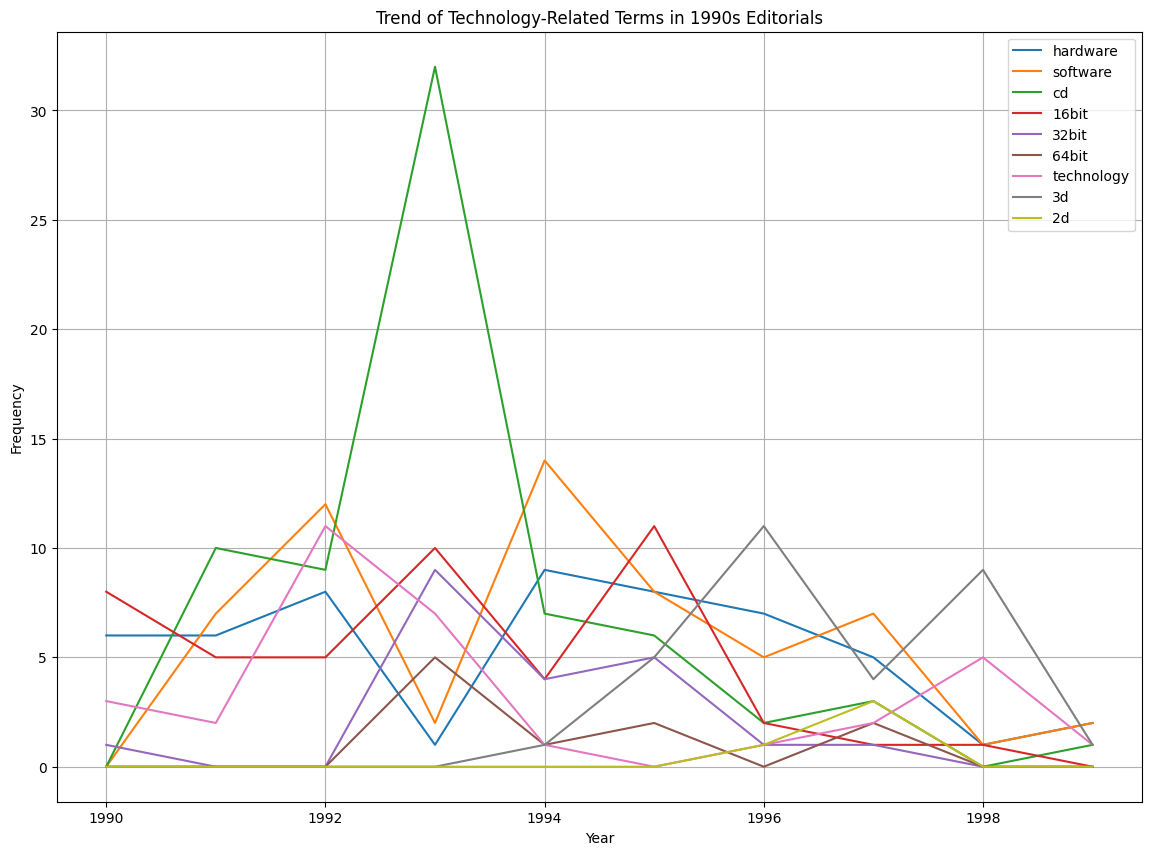

In [ ]:


# Filter necessary columns and inspect the 'tokens' column
df_filtered = df[['year', 'tokens']].copy()

# Parse 'tokens' column from string representations of lists if necessary
df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Define technology-related terms
tech_terms = ['hardware', 'software', 'cd', '16bit', '32bit', '64bit', 'technology', '3d', '2d']

# Initialize a dictionary to store term frequencies per year
yearly_term_freq = {term: [] for term in tech_terms}
years = sorted(df_filtered['year'].unique())

# Compute term frequencies for each year
for year in years:
    year_data = df_filtered[df_filtered['year'] == year]
    year_tokens = []
    for tokens in year_data['tokens']:
        year_tokens.extend(tokens)
    year_word_freq = Counter(year_tokens)
    for term in tech_terms:
        yearly_term_freq[term].append(year_word_freq[term])

# Plot the trend lines for each term
plt.figure(figsize=(14, 10))
for term, freqs in yearly_term_freq.items():
    plt.plot(years, freqs, label=term)

plt.xlabel('Year')
plt.ylabel('Frequency')
plt.title('Trend of Technology-Related Terms in 1990s Editorials')
plt.legend()
plt.grid(True)
plt.show()

C:\Users\70794\AppData\Local\Temp\ipykernel_23308\2143153416.py:9: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)


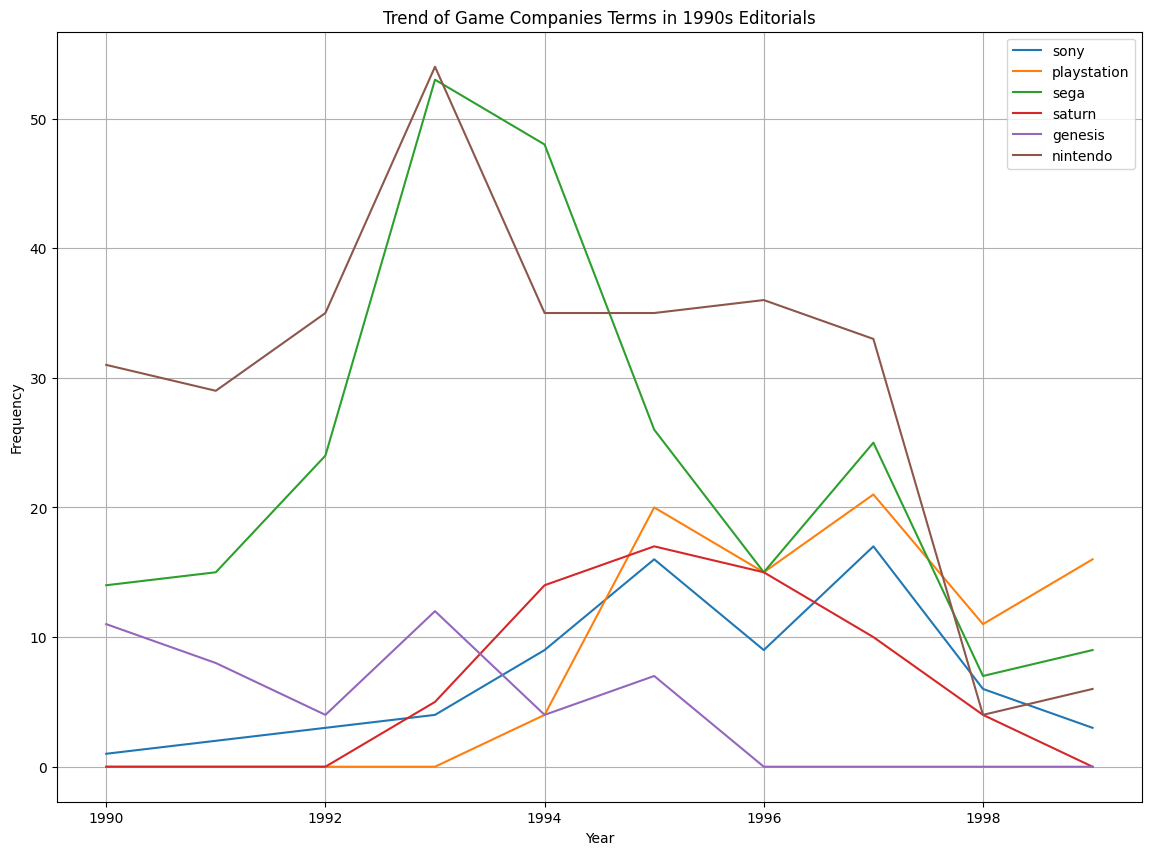

In [ ]:
# Filter necessary columns and inspect the 'tokens' column
df_filtered = df[['year', 'tokens']].copy()

# Parse 'tokens' column from string representations of lists if necessary
df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Define gaming company and console terms
tech_terms = ['sony', 'playstation', 'sega', 'saturn', 'genesis', 'nintendo']

# Initialize a dictionary to store term frequencies per year
yearly_term_freq = {term: [] for term in tech_terms}
years = sorted(df_filtered['year'].unique())

# Compute term frequencies for each year
for year in years:
    year_data = df_filtered[df_filtered['year'] == year]
    year_tokens = []
    for tokens in year_data['tokens']:
        year_tokens.extend(tokens)
    year_word_freq = Counter(year_tokens)
    for term in tech_terms:
        yearly_term_freq[term].append(year_word_freq[term])

# Plot the trend lines for each term
plt.figure(figsize=(14, 10))
for term, freqs in yearly_term_freq.items():
    plt.plot(years, freqs, label=term)

plt.xlabel('Year')
plt.ylabel('Frequency')
plt.title('Trend of Game Companies Terms in 1990s Editorials')
plt.legend()
plt.grid(True)
plt.show()

In [51]:
term_freq_df = pd.DataFrame(yearly_term_freq, index=years)

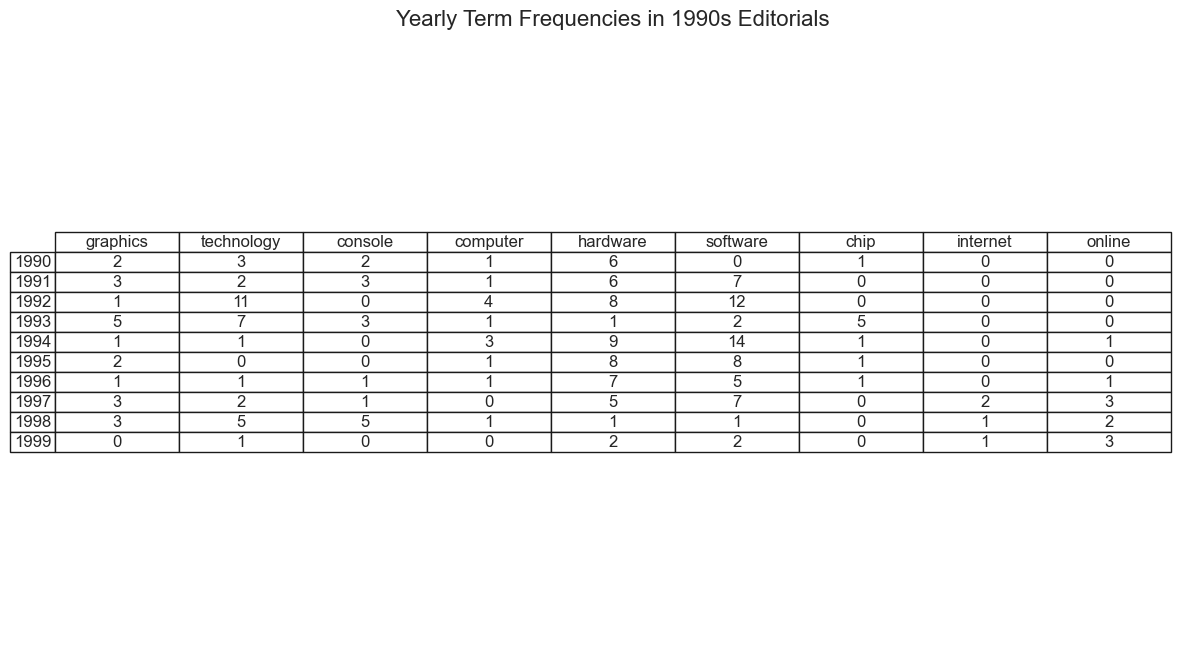

In [ ]:
# Create a new figure and axes object
fig, ax = plt.subplots(figsize=(12, 8))  # Adjust table size

# Hide the axes
ax.xaxis.set_visible(False) 
ax.yaxis.set_visible(False)
ax.set_frame_on(False)

# Render the table
tbl = ax.table(
    cellText=term_freq_df.values,
    colLabels=term_freq_df.columns,
    rowLabels=term_freq_df.index,
    cellLoc='center',
    loc='center'
)

# Customize table appearance and scale
tbl.auto_set_font_size(False)
tbl.set_fontsize(12)
tbl.scale(1.2, 1.2)

plt.title('Yearly Term Frequencies in 1990s Editorials', fontsize=16)
plt.show()

C:\Users\70794\AppData\Local\Temp\ipykernel_20096\823349646.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)
C:\Users\70794\AppData\Local\Temp\ipykernel_20096\823349646.py:19: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  result_df = pd.DataFrame(index=index, columns=game_companies).fillna(0)


<Figure size 1800x1000 with 0 Axes>

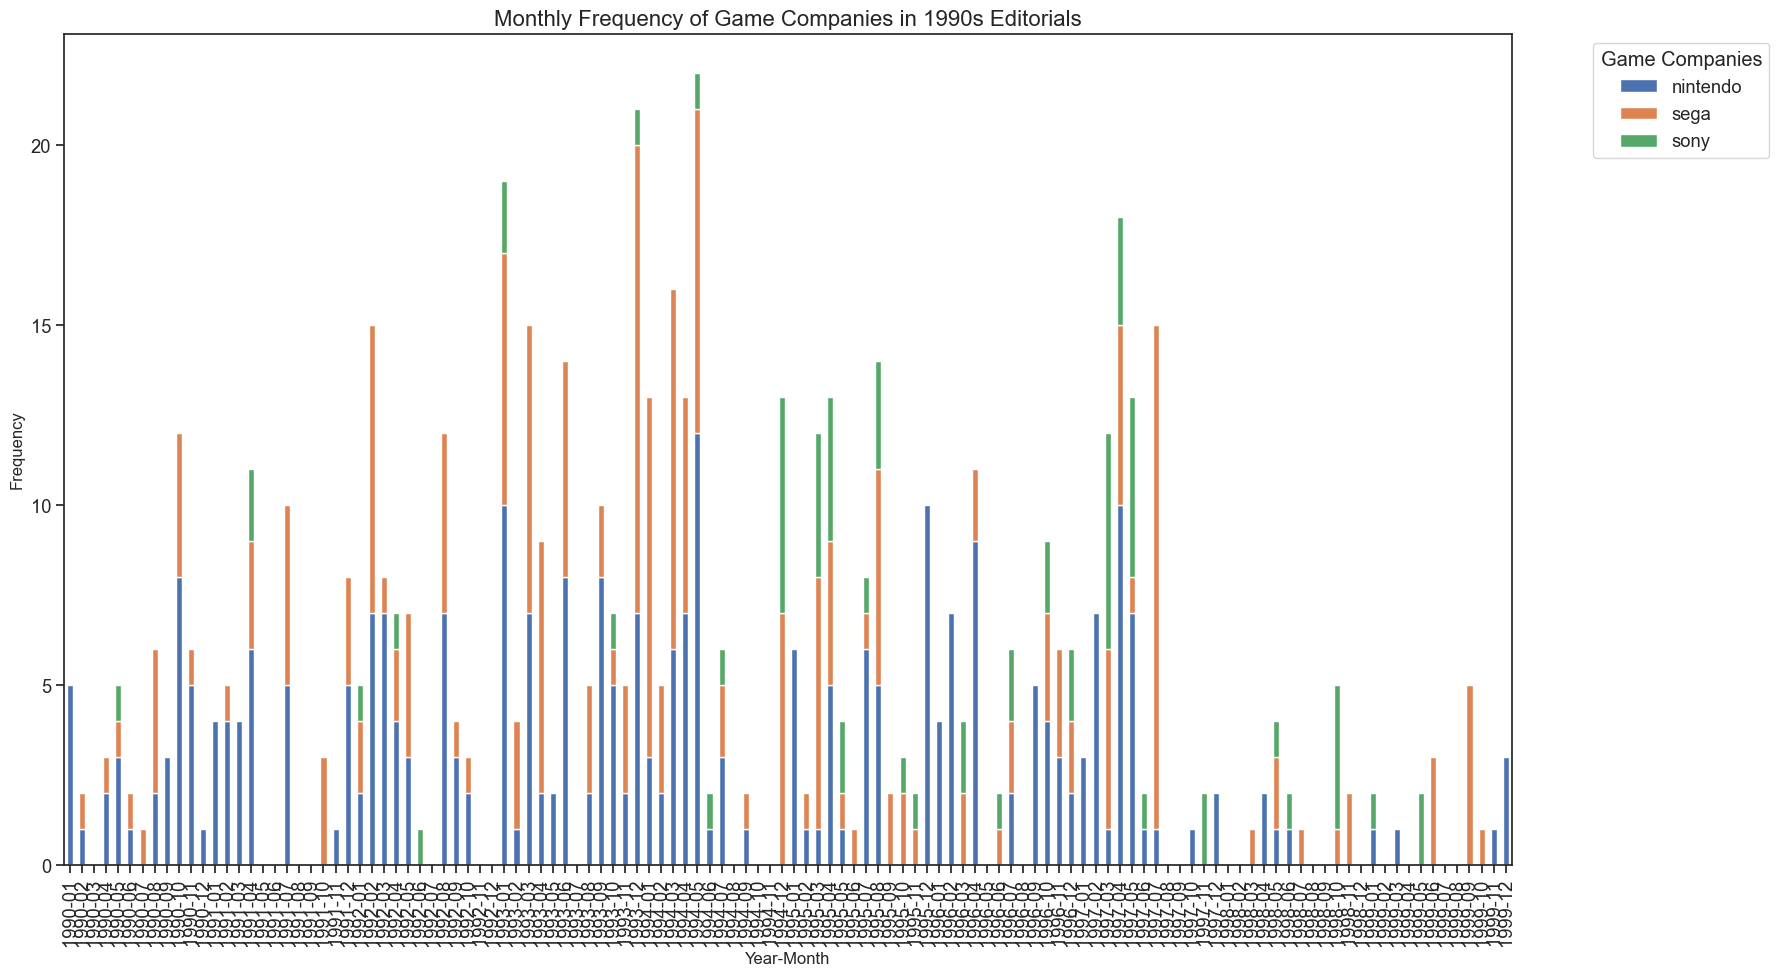

In [ ]:
# Filter necessary columns and inspect the 'tokens' column
df_filtered = df[['year', 'month', 'tokens']].copy()

# Parse 'tokens' column from string representations of lists if necessary
df_filtered['tokens'] = df_filtered['tokens'].apply(lambda x: ast.literal_eval(x) if isinstance(x, str) else x)

# Define game company names
game_companies = ['nintendo', 'sega', 'sony']

# Initialize a dictionary to store company frequencies per year and month
monthly_company_freq = {company: [] for company in game_companies}
months = sorted(df_filtered['month'].unique())
years = sorted(df_filtered['year'].unique())

# Create a MultiIndex containing all combinations of years and months
index = pd.MultiIndex.from_product([years, months], names=['Year', 'Month'])

# Initialize the result DataFrame
result_df = pd.DataFrame(index=index, columns=game_companies).fillna(0)

# Compute company name frequencies for each month and year
for year in years:
    for month in months:
        month_data = df_filtered[(df_filtered['year'] == year) & (df_filtered['month'] == month)]
        month_tokens = []
        for tokens in month_data['tokens']:
            month_tokens.extend(tokens)
        month_word_freq = Counter(month_tokens)
        for company in game_companies:
            result_df.loc[(year, month), company] = month_word_freq[company]

# Reset index for plotting convenience
result_df = result_df.reset_index()

# Combine Year and Month into a single formatted string column for plotting
result_df['YearMonth'] = result_df['Year'].astype(str) + '-' + result_df['Month'].astype(str).str.zfill(2)

# Set figure dimensions
plt.figure(figsize=(18, 10))

# Plot the stacked bar chart
result_df.set_index('YearMonth')[game_companies].plot(kind='bar', stacked=True, figsize=(18, 10))

# Configure plot title and axis labels
plt.title('Monthly Frequency of Game Companies in 1990s Editorials', fontsize=16)
plt.xlabel('Year-Month', fontsize=12)
plt.ylabel('Frequency', fontsize=12)
plt.xticks(rotation=90)
plt.legend(title='Game Companies', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

In [9]:
!pip install --upgrade scipy
!pip install --upgrade pyLDAvis


  Obtaining dependency information for scipy from https://files.pythonhosted.org/packages/4a/48/4513a1a5623a23e95f94abd675ed91cfb19989c58e9f6f7d03990f6caf3d/scipy-1.13.1-cp311-cp311-win_amd64.whl.metadata
     ---------------------------------------- 0.0/60.6 kB ? eta -:--:--
     --------------------------------- ------ 51.2/60.6 kB 1.3 MB/s eta 0:00:01
     ---------------------------------------- 60.6/60.6 kB 1.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/46.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/46.2 MB 6.0 MB/s eta 0:00:08
    --------------------------------------- 0.7/46.2 MB 6.9 MB/s eta 0:00:07
    --------------------------------------- 1.1/46.2 MB 7.8 MB/s eta 0:00:06
   - -------------------------------------- 1.6/46.2 MB 8.5 MB/s eta 0:00:06
   - -------------------------------------- 1.7/46.2 MB 9.1 MB/s eta 0:00:05
   - -------------------------------------- 2.1/46.2 MB 7.4 MB/s eta 0:00:06
   -- -------------------------

ERROR: Could not install packages due to an OSError: [WinError 5] Access is denied: 'C:\\Users\\70794\\AppData\\Roaming\\Python\\Python311\\site-packages\\~cipy.libs\\libopenblas_v0.3.26-382-gb1e8ba50--72a863714eca5a50b38260dedc0c2f3a.dll'
Consider using the `--user` option or check the permissions.



  Obtaining dependency information for pyLDAvis from https://files.pythonhosted.org/packages/6b/5a/66364c6799f2362bfb9b7100bc1ce6ffcdfe7f17e8d2e85a591bfe427643/pyLDAvis-3.4.1-py3-none-any.whl.metadata
  Obtaining dependency information for funcy from https://files.pythonhosted.org/packages/d5/08/c2409cb01d5368dcfedcbaffa7d044cc8957d57a9d0855244a5eb4709d30/funcy-2.0-py2.py3-none-any.whl.metadata
  Obtaining dependency information for FuzzyTM>=0.4.0 from https://files.pythonhosted.org/packages/2d/30/074bac7a25866a2807c1005c7852c0139ac22ba837871fc01f16df29b9dc/FuzzyTM-2.0.9-py3-none-any.whl.metadata
  Obtaining dependency information for pyfume from https://files.pythonhosted.org/packages/ed/ea/a3b120e251145dcdb10777f2bc5f18b1496fd999d705a178c1b0ad947ce1/pyFUME-0.3.4-py3-none-any.whl.metadata
  Obtaining dependency information for scipy from https://files.pythonhosted.org/packages/65/76/903324159e4a3566e518c558aeb21571d642f781d842d8dd0fd9c6b0645a/scipy-1.10.1-cp311-cp311-win_amd64.whl.met

In [ ]:

df['content'] = df['content'].fillna('')


In [ ]:


# Download NLTK stopwords if not already present
nltk.download('stopwords')

# Define custom stopwords
custom_stopwords = set([
    'game', 'games',  # Add your custom stopwords here
    'video', 'gaming', 'egm', 'magazine'
])

# Combine NLTK stopwords with custom stopwords
combined_stopwords = set(stopwords.words('english')).union(custom_stopwords)

# Convert combined_stopwords to a list
combined_stopwords_list = list(combined_stopwords)

# Create lists for the data.
training_data = []
original_texts = []
titles = []

# Define a function to clean data
def preprocess_text(text, title):
    # Remove everything I don't need
    processed_text = little_mallet_wrapper.process_string(
        text, 
        numbers='remove', 
        lowercase=True, 
        remove_stop_words=True, 
        remove_punctuation=True,
        stop_words=combined_stopwords_list  # Use the combined stopwords list
    )
    # Add the cleaned data into the lists
    training_data.append(processed_text)
    original_texts.append(text)
    titles.append(title)

# Assuming df is your DataFrame with 'content' and 'id' columns
df.apply(lambda x: preprocess_text(x['content'], x['id']), axis=1)

# To ensure the custom stopwords are being applied correctly
print("Custom stopwords have been added successfully.")


Custom stopwords have been added successfully.


[nltk_data] Downloading package stopwords to
[nltk_data]     C:\Users\70794\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!


In [8]:
# Applying the preprocess function to the data frame, we take the content for cleaning and title for identification
df.apply(lambda x: preprocess_text(x['content'], 
                                            x['id']), 
                  axis=1)

0      None
1      None
2      None
3      None
4      None
       ... 
115    None
116    None
117    None
118    None
119    None
Length: 120, dtype: object

In [70]:
!pip install nltk vaderSentiment


  Obtaining dependency information for vaderSentiment from https://files.pythonhosted.org/packages/76/fc/310e16254683c1ed35eeb97386986d6c00bc29df17ce280aed64d55537e9/vaderSentiment-3.3.2-py2.py3-none-any.whl.metadata
   ---------------------------------------- 0.0/126.0 kB ? eta -:--:--
   -------------------------- ------------- 81.9/126.0 kB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 126.0/126.0 kB 2.5 MB/s eta 0:00:00


In [ ]:

# Number of topics to return
num_topics = 3
# Numer of topic words to print out
num_topic_words = 10

# Intialize the model
model = tp.LDAModel(k=num_topics)

# Add each document to the model, after splitting it up into words
for text in training_data:
    model.add_doc(text.strip().split())

print("Topic Model Training...\n\n")
# Iterate over the data 10 times
iterations = 10
for i in range(0, 100, iterations):
    model.train(iterations)
    print(f'Iteration: {i}\tLog-likelihood: {model.ll_per_word}')


Topic Model Training...


Iteration: 0	Log-likelihood: -8.364849015176613
Iteration: 10	Log-likelihood: -8.176583231207292
Iteration: 20	Log-likelihood: -8.123097213186846
Iteration: 30	Log-likelihood: -8.092329446578324
Iteration: 40	Log-likelihood: -8.072961458952152
Iteration: 50	Log-likelihood: -8.05562962306517
Iteration: 60	Log-likelihood: -8.041855288781186
Iteration: 70	Log-likelihood: -8.028732486745449
Iteration: 80	Log-likelihood: -8.019612316544427
Iteration: 90	Log-likelihood: -8.016571894879284


In [ ]:
# Print out top 10 words for each topic
print("\nTopic Model Results:\n\n")

# Create lists to save the topics and words
topics = []
topic_individual_words = []

for topic_number in range(0, num_topics):
    topic_words = ' '.join(word for word, prob in model.get_topic_words(topic_id=topic_number, top_n=num_topic_words))
    topics.append(topic_words)
    topic_individual_words.append(topic_words.split())
    print(f"✨Topic {topic_number}✨\n\n{topic_words}\n")


Topic Model Results:


✨Topic 0✨

star movie first zelda something enough pretty wars goldeneye last

✨Topic 1✨

industry like time also every things point good yet get

✨Topic 2✨

many percent readers always like support reviews harris read information

✨Topic 3✨

one players nintendo fighter street companies want review back also

✨Topic 4✨

month next see even electronic well special look big make

✨Topic 5✨

one really year going time lot people make get way

✨Topic 6✨

new super nintendo nes issue system players year play genesis

✨Topic 7✨

sega show great two ces consumer take version play see

✨Topic 8✨

like first systems new software show also hardware still news

✨Topic 9✨

system sega nintendo new would playstation price japan sony saturn



In [33]:
df_1994 = df[df['year'] == 1994]


In [64]:
df_1994

,id,topic,content,year,month,tokens,year_month,sentiment
0,54,Violence in Video Games Part 2!,\nVideo game violence is in the news again. Th...,1994,1,"['video', 'game', 'violence', 'news', 'time', ...",1994_1,-0.030592
1,55,The Winners and Losers of Censorship,\nI caught the replay of the Senate Hearings o...,1994,2,"['caught', 'replay', 'senate', 'hearings', 'vi...",1994_2,-0.005476
2,56,Sega Sets The Pace for 1994!,\nThis is going to be a very good year for Seg...,1994,3,"['going', 'good', 'year', 'sega', 'dominated',...",1994_3,0.124495
3,57,Video Game Systems Are Just Expensive Toys,\nA couple of days ago Nintendo announced that...,1994,4,"['couple', 'days', 'ago', 'nintendo', 'announc...",1994_4,0.033945
4,58,Sega vs. Nintendo U.S. vs. Japan,\nI see that Sega and Nintendo are back at eac...,1994,5,"['see', 'sega', 'nintendo', 'back', 'others', ...",1994_5,0.096787
5,59,EGM Selected As Best U.S. Game Magazine at ECTS!,\nWe're quite pleased. It's always a great hon...,1994,6,"['quite', 'pleased', 'always', 'great', 'honor...",1994_6,0.105104
6,60,The Flood Waters Are Rising,\nWith the apparent death of the faithful Nint...,1994,7,"['apparent', 'death', 'faithful', 'nintendo', ...",1994_7,0.108274
7,61,No More Street Fighter II!,\nWe received our finished copy of Super Stree...,1994,8,"['received', 'finished', 'copy', 'super', 'str...",1994_8,0.048990
8,62,How Could You Do This?,\nNo matter how many people look at the same i...,1994,9,"['matter', 'many', 'people', 'look', 'issue', ...",1994_9,0.069979
9,63,Making a Statement,\nI've received hundreds of letters about my c...,1994,10,"['ive', 'received', 'hundreds', 'letters', 'co...",1994_10,0.037687


In [ ]:
# Generate the topic model using the filtered dataset
# Assuming `model` is your instantiated topic model object trained on filtered data:
# model = TopicModel(df_1994['text_column'])

# Define the number of topics and words per topic
num_topics = 3
num_topic_words = 10

# Print topic model results
print("\nTopic Model Results:\n\n")

# Initialize lists to store topics and word tokens
topics = []
topic_individual_words = []

for topic_number in range(0, num_topics):
    topic_words = ' '.join(word for word, prob in model.get_topic_words(topic_id=topic_number, top_n=num_topic_words))
    topics.append(topic_words)
    topic_individual_words.append(topic_words.split())
    print(f"✨Topic {topic_number}✨\n\n{topic_words}\n")


Topic Model Results:


✨Topic 0✨

new get one issue also companies make look best even

✨Topic 1✨

like industry month year first future fact playing special ever

✨Topic 2✨

nintendo sega system new systems time show would japan one



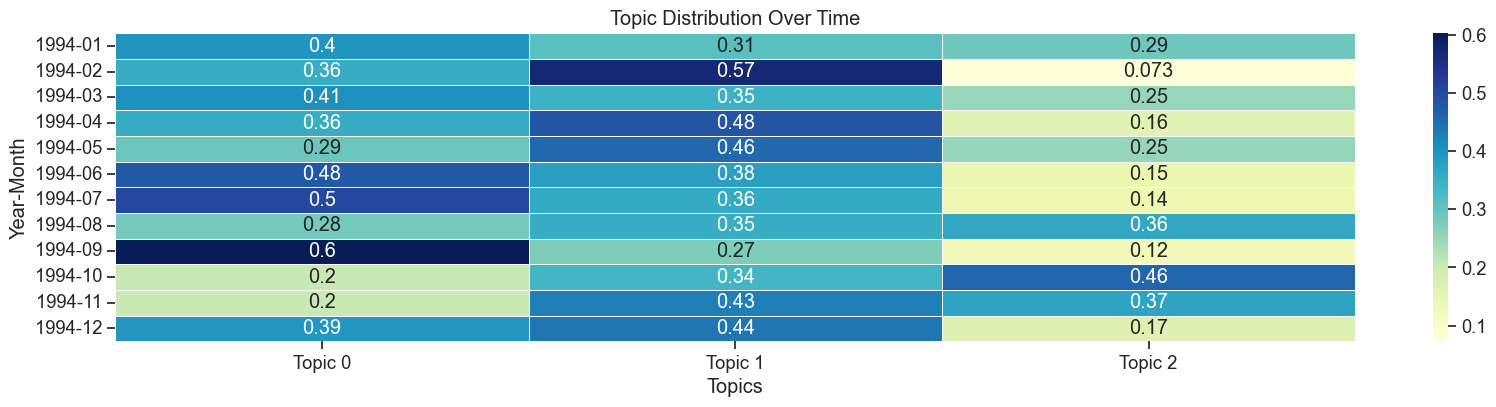

In [ ]:

# Reset index of df_1994 to ensure it has a default integer index
df_1994 = df_1994.reset_index(drop=True)

# Ensure model.docs and df_1994 are aligned
aligned_docs = model.docs[:len(df_1994)]

# Create a DataFrame to store year_month and topic probability for each document
data = []
for doc_id, doc in enumerate(aligned_docs):
    year_month = df_1994.at[doc_id, 'year_month']  # Use .at instead of .loc
    topic_probs = doc.get_topics()
    for topic_id, prob in topic_probs:
        data.append([year_month, topic_id, prob])

# Create DataFrame
df_prob = pd.DataFrame(data, columns=['year_month', 'topic_id', 'prob'])

# Correct the format of year_month and convert it to datetime type
df_prob['year_month'] = df_prob['year_month'].apply(lambda x: f"{x.split('_')[0]}-{int(x.split('_')[1]):02d}")
df_prob['year_month'] = pd.to_datetime(df_prob['year_month'], format='%Y-%m')

# Calculate the mean probability for each year_month and topic_id
df_prob_mean = df_prob.groupby(['year_month', 'topic_id'])['prob'].mean().unstack()

# Ensure only the actual number of topics is reflected in column names
num_topics = df_prob['topic_id'].nunique()
df_prob_mean.columns = [f'Topic {i}' for i in range(num_topics)]

# Ensure the index is sorted in chronological order
df_prob_mean = df_prob_mean.sort_index()

# Format the year_month index to display only year and month
df_prob_mean.index = df_prob_mean.index.to_period('M').strftime('%Y-%m')

# Adjust plot size
plt.figure(figsize=(20, 4))

# Plot heatmap using seaborn
sns.heatmap(df_prob_mean, annot=True, cmap="YlGnBu", linewidths=.5)

# Set title and labels for the heatmap
plt.title('Topic Distribution Over Time')
plt.xlabel('Topics')
plt.ylabel('Year-Month')

# Show heatmap
plt.show()


In [ ]:

# Step 1: Define the topics and their associated words
topics = {
    "A": ["new", "get", "one", "issue", "also", "companies", "make", "look", "best", "even"],
    "B": ["like", "industry", "month", "year", "first", "future", "fact", "playing", "special", "ever"],
    "C": ["nintendo", "sega", "system", "new", "systems", "time", "show", "would", "japan", "one"]
}

# Load the dataset
data = df_1994

# Drop rows with NaN values in the 'content' column
data_cleaned = data.dropna(subset=['content'])

# Function to calculate sentiment score using TextBlob
def calculate_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity

# Step 2: Match each content to the most relevant topics
def match_topics(text, topics):
    tokens = text.lower().split()
    topic_scores = defaultdict(int)
    for token in tokens:
        for topic, words in topics.items():
            if token in words:
                topic_scores[topic] += 1
    sorted_topics = sorted(topic_scores.items(), key=lambda item: item[1], reverse=True)
    return [topic for topic, score in sorted_topics[:3]] if sorted_topics else [None, None, None]

# Match each content to the top 3 topics
data_cleaned[['top_topic_1', 'top_topic_2', 'top_topic_3']] = data_cleaned['content'].apply(lambda x: pd.Series(match_topics(x, topics)))

# Calculate sentiment score for each content
data_cleaned['sentiment_score'] = data_cleaned['content'].apply(calculate_sentiment)

# Calculate average sentiment score for each topic
topic_sentiment = {}
for topic_id in topics.keys():
    topic_docs = data_cleaned[data_cleaned.apply(lambda row: topic_id in [row['top_topic_1'], row['top_topic_2'], row['top_topic_3']], axis=1)]
    avg_sentiment = topic_docs['sentiment_score'].mean()
    topic_sentiment[f'Topic {topic_id}'] = avg_sentiment

# Convert the results to a DataFrame
df_topic_sentiment = pd.DataFrame(list(topic_sentiment.items()), columns=['Topic', 'Average Sentiment Score'])


In [66]:
data_cleaned

,id,topic,content,year,month,tokens,year_month,sentiment,top_topic_1,top_topic_2,top_topic_3,sentiment_score
0,54,Violence in Video Games Part 2!,\nVideo game violence is in the news again. Th...,1994,1,"['video', 'game', 'violence', 'news', 'time', ...",1994_1,-0.030592,2,0,1,-0.030592
1,55,The Winners and Losers of Censorship,\nI caught the replay of the Senate Hearings o...,1994,2,"['caught', 'replay', 'senate', 'hearings', 'vi...",1994_2,-0.005476,0,2,1,-0.005476
2,56,Sega Sets The Pace for 1994!,\nThis is going to be a very good year for Seg...,1994,3,"['going', 'good', 'year', 'sega', 'dominated',...",1994_3,0.124495,2,1,0,0.124495
3,57,Video Game Systems Are Just Expensive Toys,\nA couple of days ago Nintendo announced that...,1994,4,"['couple', 'days', 'ago', 'nintendo', 'announc...",1994_4,0.033945,2,0,1,0.033945
4,58,Sega vs. Nintendo U.S. vs. Japan,\nI see that Sega and Nintendo are back at eac...,1994,5,"['see', 'sega', 'nintendo', 'back', 'others', ...",1994_5,0.096787,2,0,1,0.096787
5,59,EGM Selected As Best U.S. Game Magazine at ECTS!,\nWe're quite pleased. It's always a great hon...,1994,6,"['quite', 'pleased', 'always', 'great', 'honor...",1994_6,0.105104,2,0,1,0.105104
6,60,The Flood Waters Are Rising,\nWith the apparent death of the faithful Nint...,1994,7,"['apparent', 'death', 'faithful', 'nintendo', ...",1994_7,0.108274,2,0,1,0.108274
7,61,No More Street Fighter II!,\nWe received our finished copy of Super Stree...,1994,8,"['received', 'finished', 'copy', 'super', 'str...",1994_8,0.048990,0,2,1,0.048990
8,62,How Could You Do This?,\nNo matter how many people look at the same i...,1994,9,"['matter', 'many', 'people', 'look', 'issue', ...",1994_9,0.069979,0,2,1,0.069979
9,63,Making a Statement,\nI've received hundreds of letters about my c...,1994,10,"['ive', 'received', 'hundreds', 'letters', 'co...",1994_10,0.037687,0,1,2,0.037687


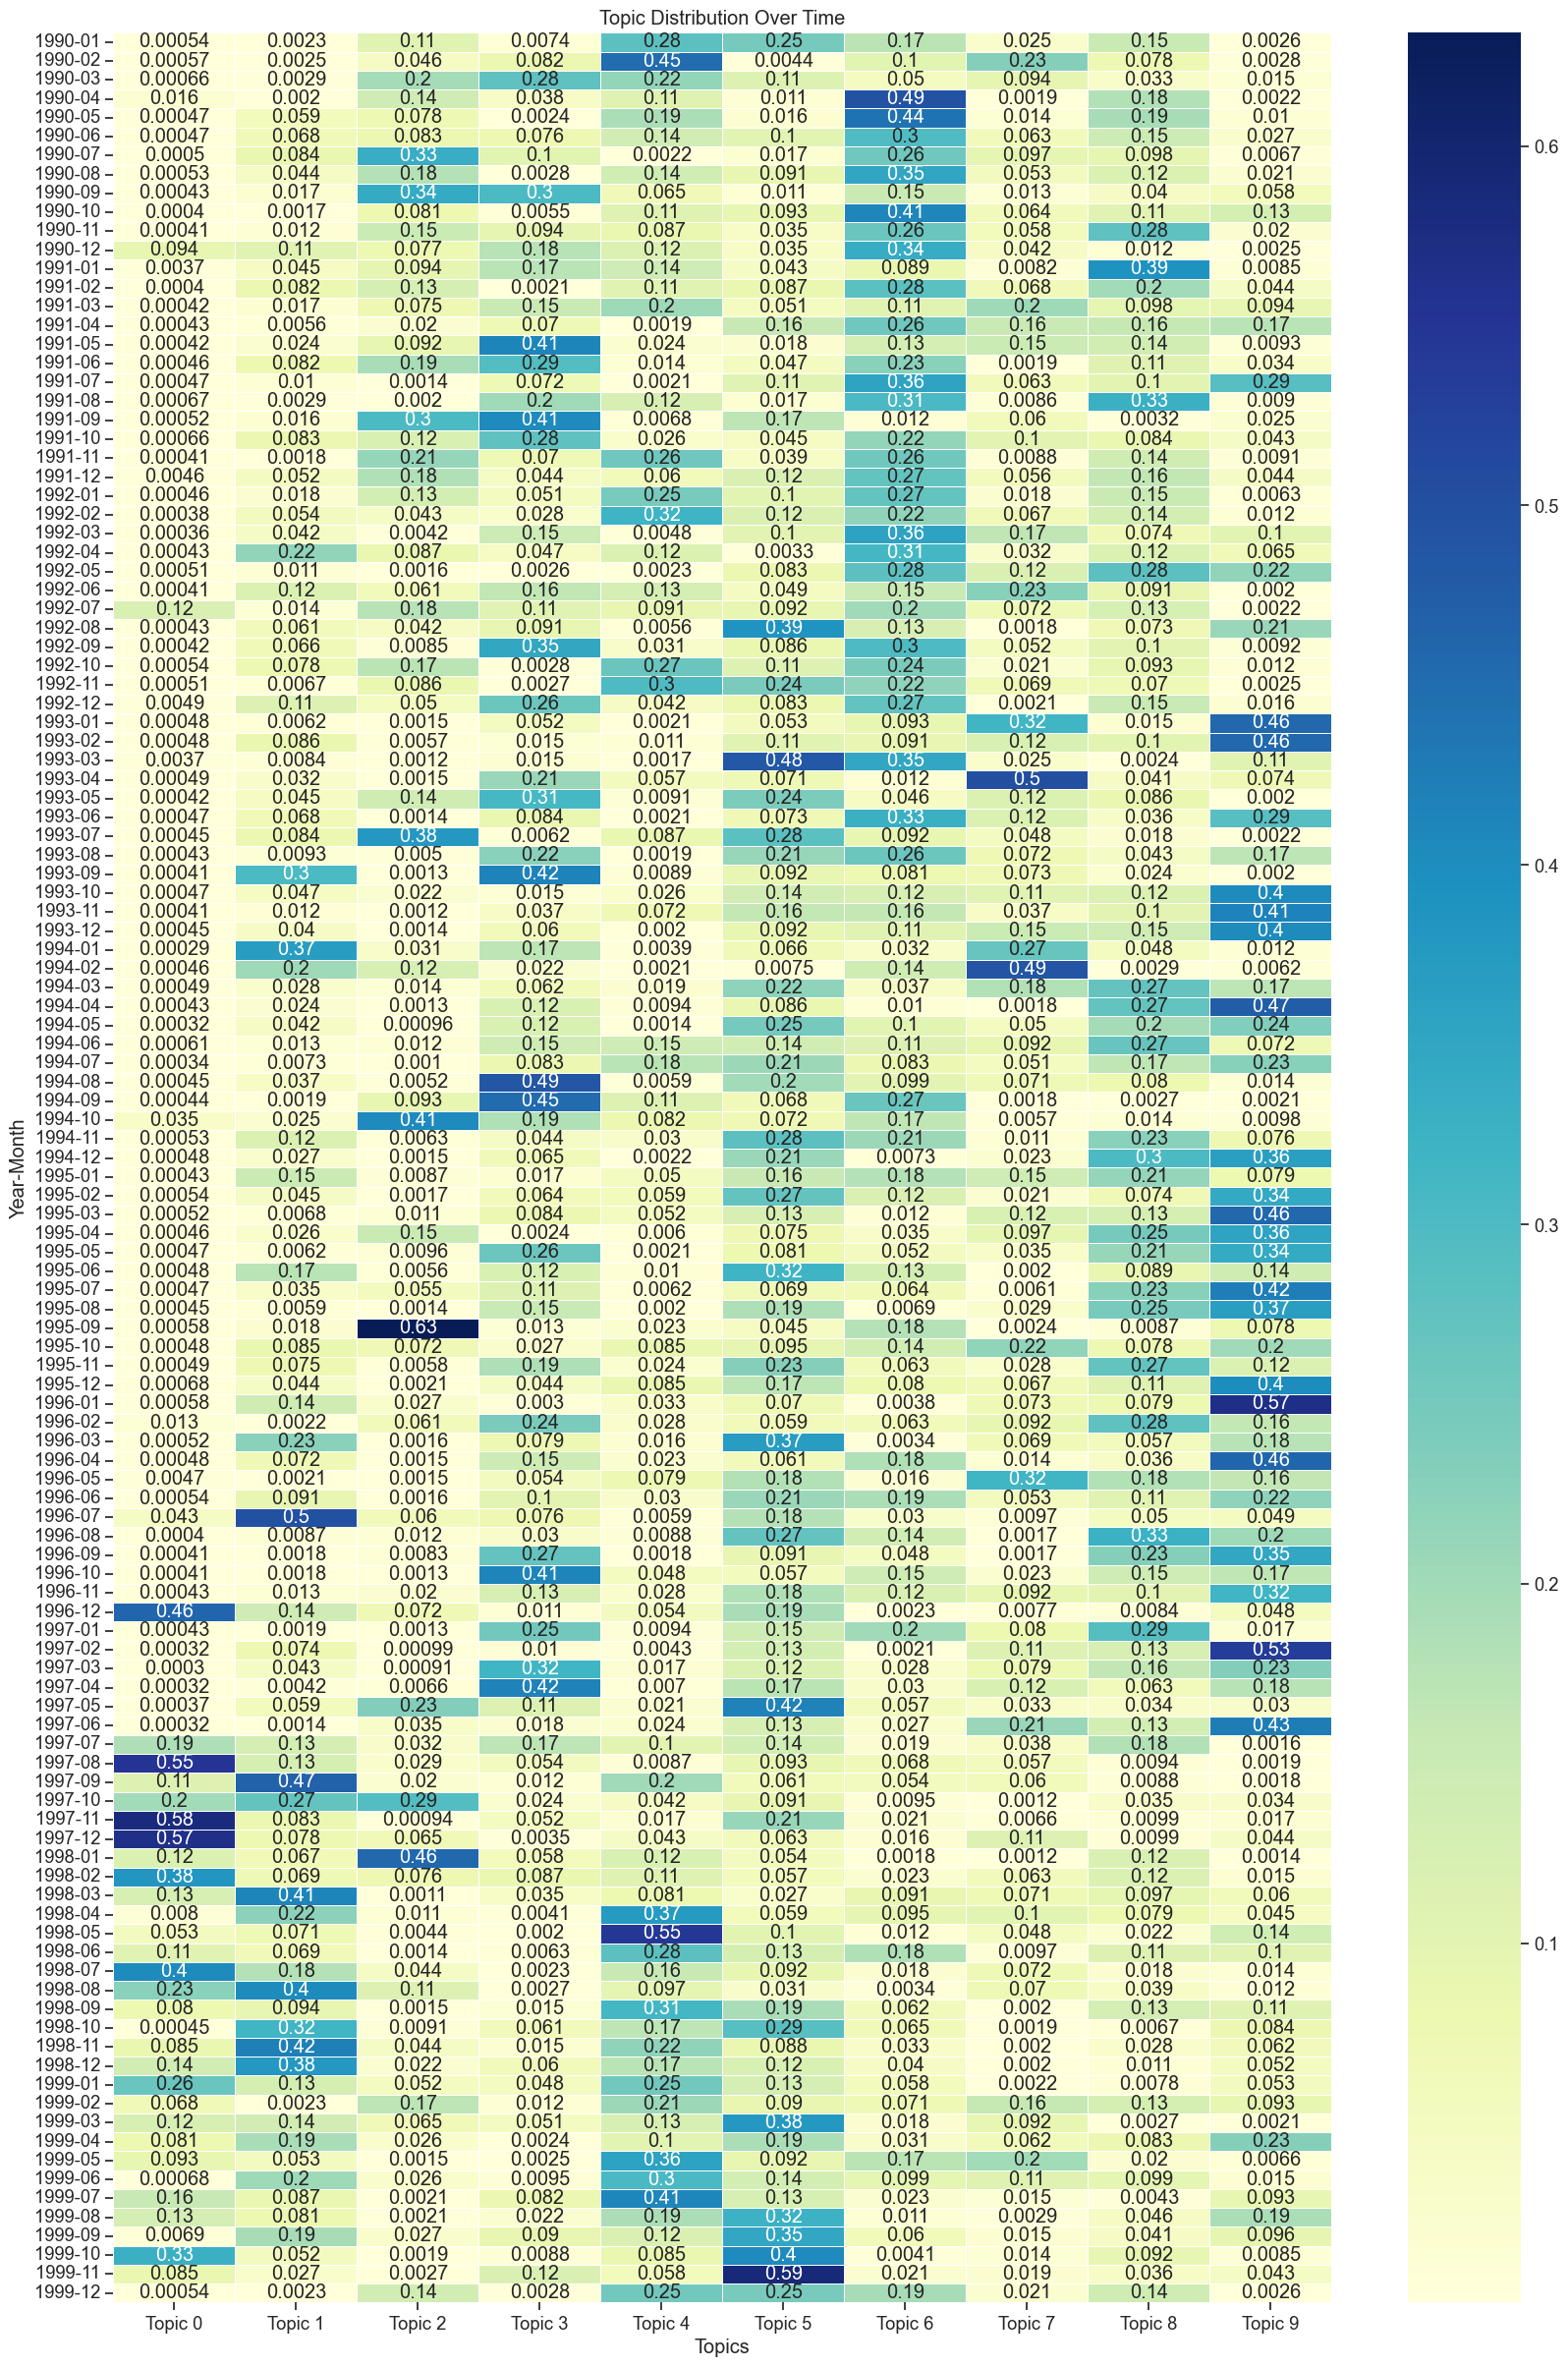

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure model.docs and df are aligned
aligned_docs = model.docs[:len(df)]

# Create a DataFrame to store year_month and the topic probabilities for each document
data = []
for doc_id, doc in enumerate(aligned_docs):
    year_month = df.at[doc_id, 'year_month']  # Use .at instead of .loc
    topic_probs = doc.get_topics()
    for topic_id, prob in topic_probs:
        data.append([year_month, topic_id, prob])

# Construct the DataFrame
df_prob = pd.DataFrame(data, columns=['year_month', 'topic_id', 'prob'])

# Convert year_month to datetime format after standardizing the string structure
df_prob['year_month'] = df_prob['year_month'].apply(lambda x: f"{x.split('_')[0]}-{int(x.split('_')[1]):02d}")

# Parse corrected year_month into datetime objects
df_prob['year_month'] = pd.to_datetime(df_prob['year_month'], format='%Y-%m')

# Calculate the mean probability grouped by year_month and topic_id
df_prob_mean = df_prob.groupby(['year_month', 'topic_id'])['prob'].mean().unstack()

# Rename columns to represent topics
num_topics = len(df_prob['topic_id'].unique())
df_prob_mean.columns = [f'Topic {i}' for i in range(num_topics)]

# Ensure the index is sorted chronologically
df_prob_mean = df_prob_mean.sort_index()

# Format year_month to display only Year-Month
df_prob_mean.index = df_prob_mean.index.to_period('M').strftime('%Y-%m')

# Set figure dimensions
plt.figure(figsize=(20, 30))  # Width: 20, Height: 30

# Generate heatmap using seaborn
sns.heatmap(df_prob_mean, annot=True, cmap="YlGnBu", linewidths=.5)

# Set heatmap title and axis labels
plt.title('Topic Distribution Over Time')
plt.xlabel('Topics')
plt.ylabel('Year-Month')

# Display the heatmap
plt.show()

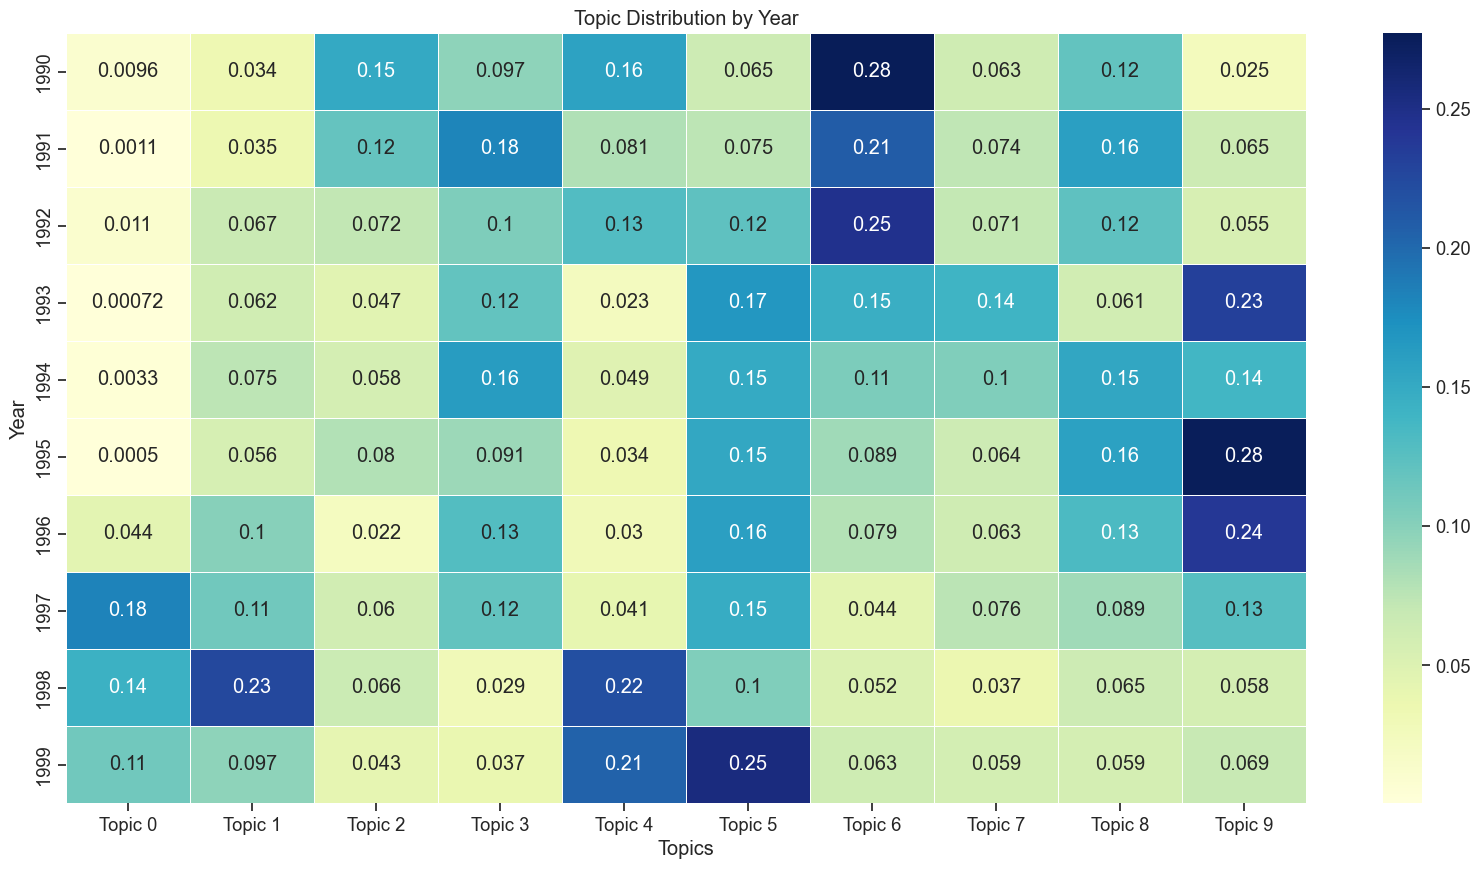

In [ ]:

# Ensure model.docs and df are aligned
aligned_docs = model.docs[:len(df)]

# Create a DataFrame to store year_month and the topic probabilities for each document
data = []
for doc_id, doc in enumerate(aligned_docs):
    year_month = df.at[doc_id, 'year_month']
    topic_probs = doc.get_topics()
    for topic_id, prob in topic_probs:
        data.append([year_month, topic_id, prob])

# Construct the DataFrame
df_prob = pd.DataFrame(data, columns=['year_month', 'topic_id', 'prob'])

# Extract the year from year_month
df_prob['year'] = df_prob['year_month'].apply(lambda x: x.split('_')[0])

# Calculate the mean probability grouped by year and topic_id
df_prob_mean_year = df_prob.groupby(['year', 'topic_id'])['prob'].mean().unstack()

# Rename columns to represent topics
num_topics = len(df_prob['topic_id'].unique())
df_prob_mean_year.columns = [f'Topic {i}' for i in range(num_topics)]

# Ensure the index is sorted chronologically
df_prob_mean_year = df_prob_mean_year.sort_index()

# Set figure dimensions
plt.figure(figsize=(20, 10))  # Width: 20, Height: 10

# Generate heatmap using seaborn
sns.heatmap(df_prob_mean_year, annot=True, cmap="YlGnBu", linewidths=.5)

# Set heatmap title and axis labels
plt.title('Topic Distribution by Year')
plt.xlabel('Topics')
plt.ylabel('Year')

# Display the heatmap
plt.show()

In [ ]:


# Assuming you have a DataFrame containing documents and their respective topics:
# df = pd.DataFrame({
#     'document': [...],  # Document text
#     'topic': [...]      # Corresponding topic ID
# })

# Define a function to calculate sentiment polarity for a given text
def get_sentiment(text):
    analysis = TextBlob(text)
    return analysis.sentiment.polarity

# Compute sentiment score for each document
df['sentiment'] = df['content'].apply(get_sentiment)

# Compute the average sentiment score for each topic
topic_sentiment = df.groupby('id')['sentiment'].mean().reset_index()
topic_sentiment.columns = ['id', 'avg_sentiment']

print(topic_sentiment)

      id  avg_sentiment
0      6       0.105112
1      7       0.065716
2      8       0.060998
3      9       0.075634
4     10       0.187278
..   ...            ...
115  121       0.140404
116  122       0.274755
117  123       0.121603
118  124       0.113243
119  125       0.127214

[120 rows x 2 columns]


In [ ]:

# List of general words to be removed
general_words = {'game', 'games', 'video', 'egm'}

# Function to get top 10 frequent tokens for each month excluding general words
def get_top_tokens_by_month_exclude_general(df, exclude_words):
    results = []
    grouped = df.groupby(['year', 'month'])
    for (year, month), group in grouped:
        all_tokens = list(itertools.chain.from_iterable(group['tokens']))
        filtered_tokens = [token for token in all_tokens if token not in exclude_words]
        counter = Counter(filtered_tokens)
        top_10 = counter.most_common(10)
        results.append({
            'year': year,
            'month': month,
            'top_10_tokens': top_10
        })
    return results

# Get the top 10 frequent tokens for each month excluding general words
top_tokens_by_month_filtered = get_top_tokens_by_month_exclude_general(df, general_words)

# Convert the results to a DataFrame
top_tokens_filtered_df = pd.DataFrame(top_tokens_by_month_filtered)

# Print the filtered results in a more readable format
for index, row in top_tokens_filtered_df.iterrows():
    print(f"Year: {row['year']}, Month: {row['month']}")
    for token, count in row['top_10_tokens']:
        print(f"  {token}: {count}")
    print("\n")

Year: 1990, Month: 1
  steven: 5
  nintendo: 5
  little: 4
  new: 3
  quite: 3
  systems: 3
  life: 2
  hot: 2
  away: 2
  day: 2


Year: 1990, Month: 2
  gaming: 8
  electronic: 6
  monthly: 6
  play: 4
  secret: 4
  top: 4
  special: 3
  youll: 3
  score: 3
  tips: 3


Year: 1990, Month: 3
  weve: 3
  letters: 3
  question: 3
  show: 3
  like: 3
  staff: 2
  hundreds: 2
  determine: 2
  exactly: 2
  recent: 2


Year: 1990, Month: 4
  new: 9
  first: 5
  handheld: 5
  story: 4
  know: 4
  magazine: 4
  information: 3
  latest: 3
  also: 3
  world: 3


Year: 1990, Month: 5
  new: 9
  systems: 6
  gaming: 4
  weve: 4
  developments: 3
  nintendo: 3
  16bit: 3
  nes: 3
  2: 3
  super: 3


Year: 1990, Month: 6
  new: 6
  get: 5
  us: 5
  make: 4
  magazine: 4
  youll: 4
  super: 3
  electronic: 2
  gaming: 2
  complete: 2


Year: 1990, Month: 7
  system: 5
  support: 4
  better: 3
  nec: 3
  manufacturers: 3
  players: 3
  get: 3
  genesis: 2
  editor: 2
  article: 2


Year: 1990, Month: 

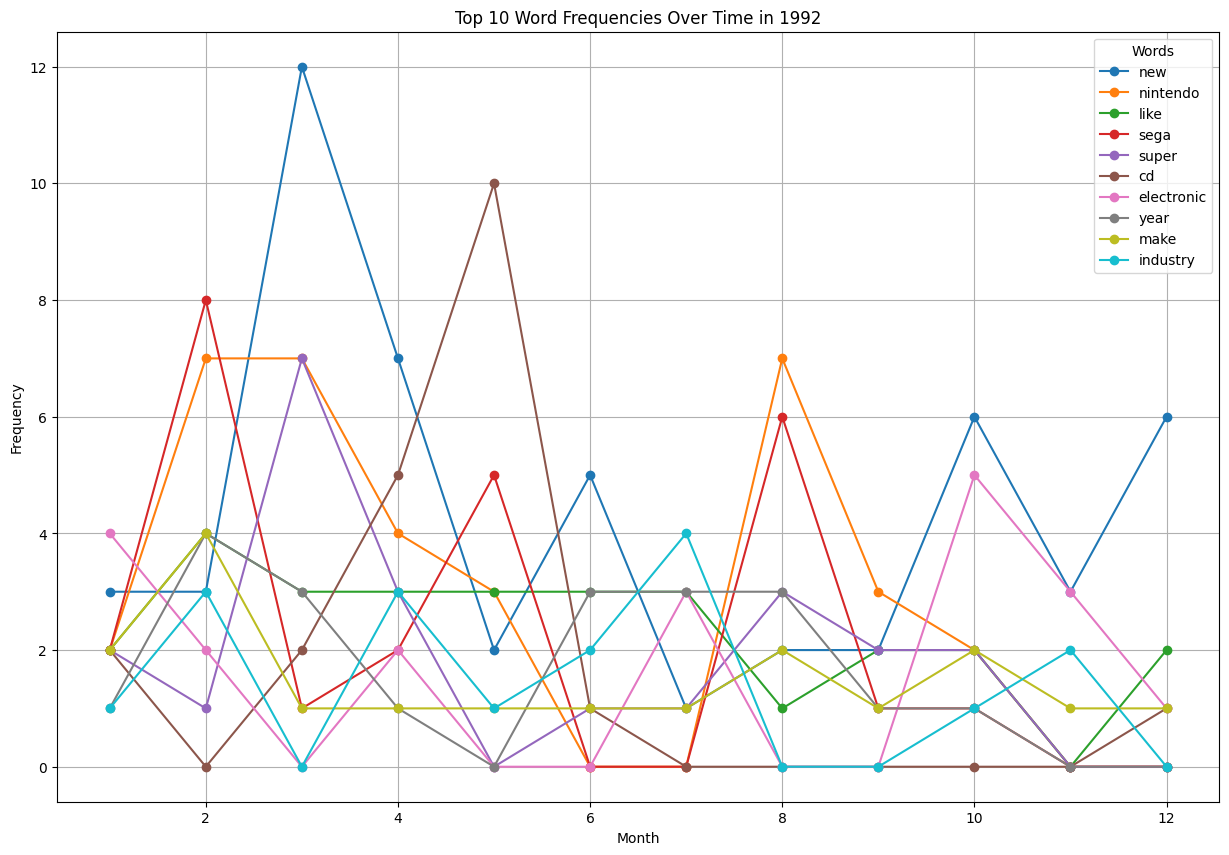

In [ ]:

data_1992 = df[df['year'] == 1992]

# Define a function to calculate word frequencies for each month, excluding specified words
def monthly_word_frequencies(data, exclude_words):
    monthly_data = {}
    for month in sorted(data['month'].unique()):
        month_content = ' '.join(data[data['month'] == month]['content'])
        vectorizer = CountVectorizer(stop_words='english', max_features=1000)
        X = vectorizer.fit_transform([month_content])
        words = vectorizer.get_feature_names_out()
        counts = X.toarray().flatten()
        word_count_dict = dict(zip(words, counts))
        filtered_word_count = {word: count for word, count in word_count_dict.items() if word not in exclude_words}
        monthly_data[month] = filtered_word_count
    return monthly_data

# Define the words to be excluded
exclude_words = ['game', 'games', 'video', 'egm', 'gaming', 'magazine']

# Calculate word frequencies for each month
monthly_freq = monthly_word_frequencies(data_1992, exclude_words)

# Convert the monthly frequencies to a DataFrame for better visualization
monthly_freq_df = pd.DataFrame(monthly_freq).fillna(0).astype(int)

# Identify the top 10 most frequent words across all months
top_10_words = monthly_freq_df.sum(axis=1).sort_values(ascending=False).head(10).index.tolist()

# Extract the data for these top 10 words
top_10_word_freq_df = monthly_freq_df.loc[top_10_words]

# Plot line charts for the top 10 words over time
plt.figure(figsize=(15, 10))

for word in top_10_words:
    plt.plot(top_10_word_freq_df.columns, top_10_word_freq_df.loc[word], marker='o', label=word)

plt.title('Top 10 Word Frequencies Over Time in 1992')
plt.xlabel('Month')
plt.ylabel('Frequency')
plt.legend(title='Words')
plt.grid(True)
plt.show()


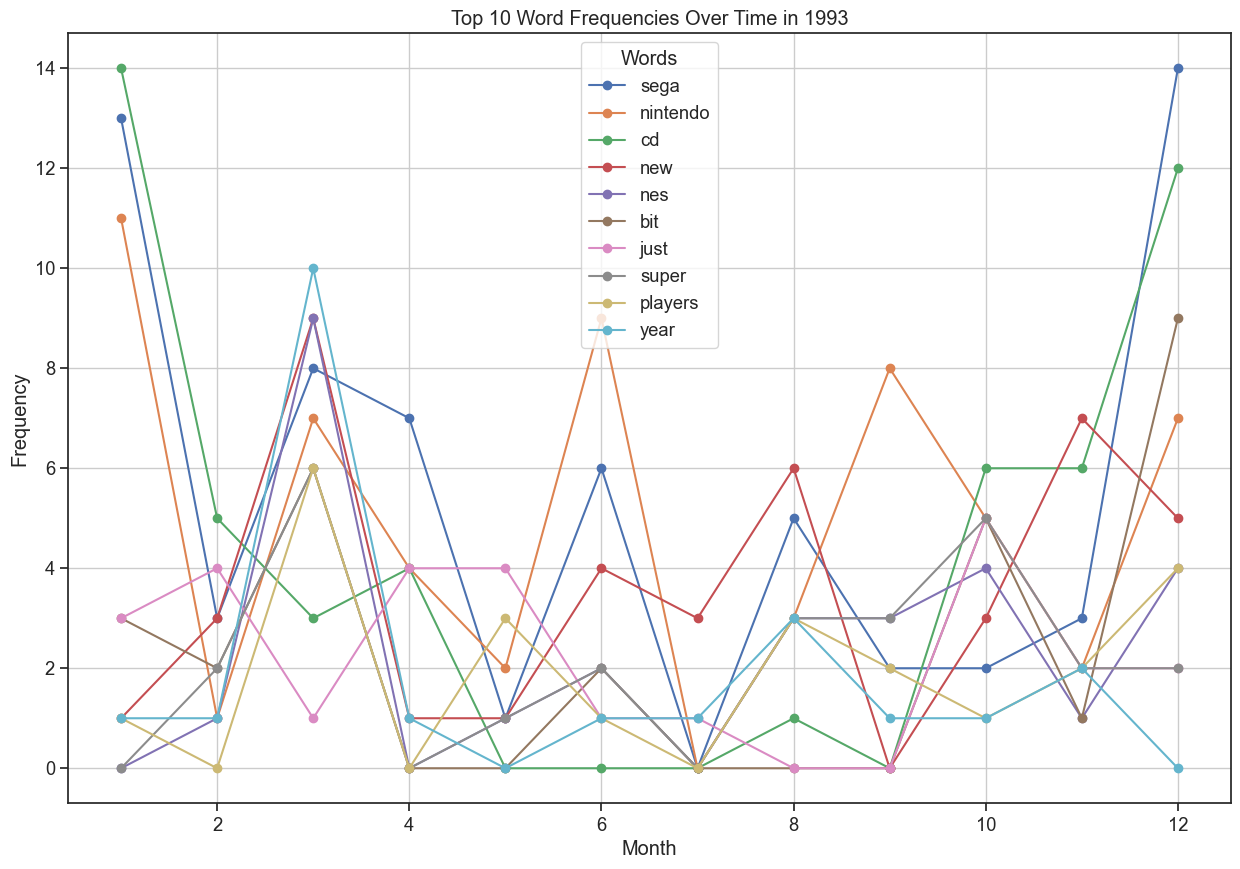

In [ ]:

data_1993 = df[df['year'] == 1993]

# Define a function to calculate word frequencies for each month, excluding specified words
def monthly_word_frequencies(data, exclude_words):
    monthly_data = {}
    for month in sorted(data['month'].unique()):
        month_content = ' '.join(data[data['month'] == month]['content'])
        vectorizer = CountVectorizer(stop_words='english', max_features=1000)
        X = vectorizer.fit_transform([month_content])
        words = vectorizer.get_feature_names_out()
        counts = X.toarray().flatten()
        word_count_dict = dict(zip(words, counts))
        filtered_word_count = {word: count for word, count in word_count_dict.items() if word not in exclude_words}
        monthly_data[month] = filtered_word_count
    return monthly_data

# Define the words to be excluded
exclude_words = ['game', 'games', 'video', 'egm', 'gaming', 'magazine']

# Calculate word frequencies for each month
monthly_freq = monthly_word_frequencies(data_1993, exclude_words)

# Convert the monthly frequencies to a DataFrame for better visualization
monthly_freq_df = pd.DataFrame(monthly_freq).fillna(0).astype(int)

# Identify the top 10 most frequent words across all months
top_10_words = monthly_freq_df.sum(axis=1).sort_values(ascending=False).head(10).index.tolist()

# Extract the data for these top 10 words
top_10_word_freq_df = monthly_freq_df.loc[top_10_words]

# Plot line charts for the top 10 words over time
plt.figure(figsize=(15, 10))

for word in top_10_words:
    plt.plot(top_10_word_freq_df.columns, top_10_word_freq_df.loc[word], marker='o', label=word)

plt.title('Top 10 Word Frequencies Over Time in 1993')
plt.xlabel('Month')
plt.ylabel('Frequency')
plt.legend(title='Words')
plt.grid(True)
plt.show()


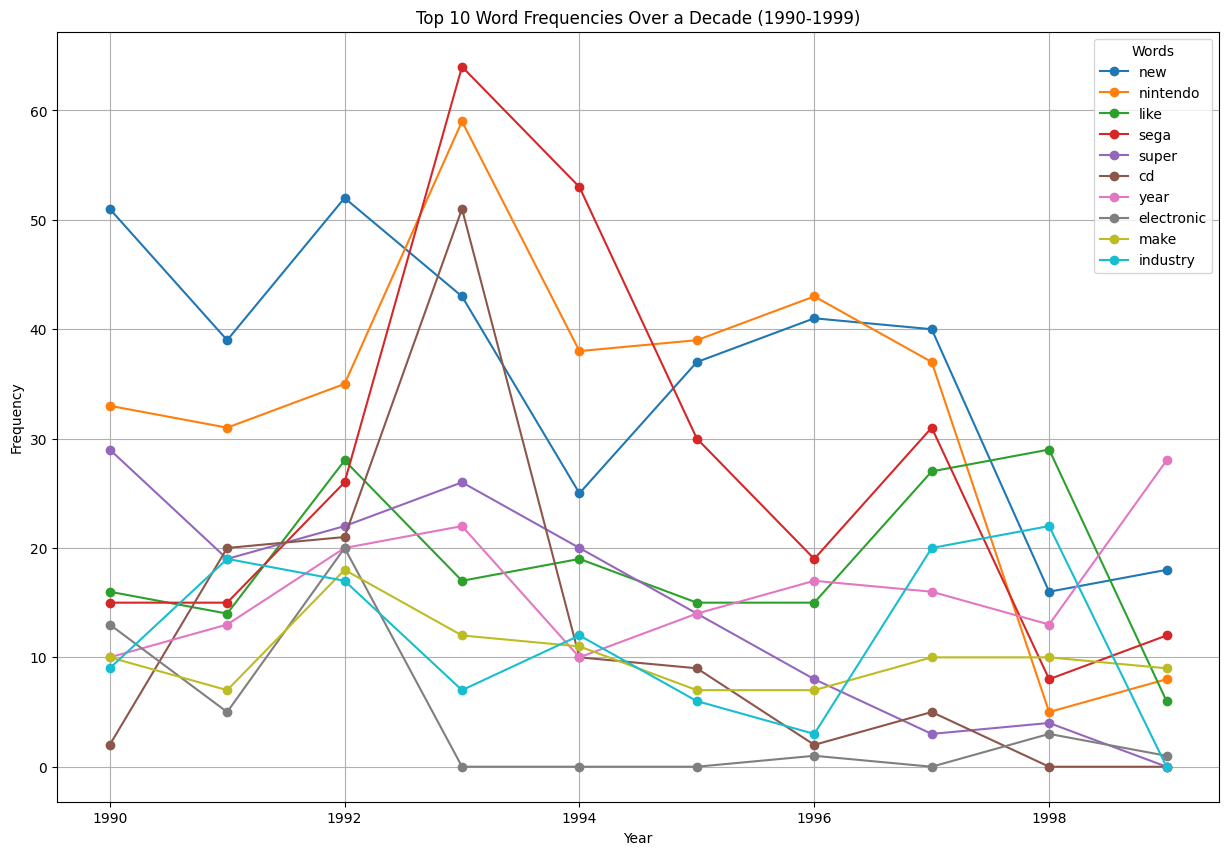

In [ ]:
# Set the time range from 1990 to 1999
start_year = 1990
end_year = 1999

# Filter the dataset to include only articles within the specified time range
data_decade = df[(df['year'] >= start_year) & (df['year'] <= end_year)].copy()

# Ensure the content column consists of string types
data_decade['content'] = data_decade['content'].astype(str)

# Define custom stopwords/words to exclude
exclude_words = ['game', 'games', 'video', 'egm', 'gaming', 'magazine']

# Define a function to calculate word frequencies per year
def yearly_word_frequencies(data, exclude_words):
    yearly_data = {}
    for year in sorted(data['year'].unique()):
        year_content = ' '.join(data[data['year'] == year]['content'])
        vectorizer = CountVectorizer(stop_words='english', max_features=1000)
        X = vectorizer.fit_transform([year_content])
        words = vectorizer.get_feature_names_out()
        counts = X.toarray().flatten()
        word_count_dict = dict(zip(words, counts))
        filtered_word_count = {word: count for word, count in word_count_dict.items() if word not in exclude_words}
        yearly_data[year] = filtered_word_count
    return yearly_data

# Calculate annual word frequencies
yearly_freq = yearly_word_frequencies(data_decade, exclude_words)

# Convert annual word frequencies to a DataFrame for easier visualization
yearly_freq_df = pd.DataFrame(yearly_freq).fillna(0).astype(int)

# Identify the top 10 most frequent words in 1992
top_10_words_1992 = yearly_freq_df[1992].sort_values(ascending=False).head(10).index.tolist()

# Extract the frequency trends of these 10 words across all years
top_10_word_freq_df_decade = yearly_freq_df.loc[top_10_words_1992]

# Plot the frequencies of these top words over the decade
plt.figure(figsize=(15, 10))

for word in top_10_words_1992:
    plt.plot(top_10_word_freq_df_decade.columns, top_10_word_freq_df_decade.loc[word], marker='o', label=word)

plt.title('Top 10 Word Frequencies Over a Decade (1990-1999)')
plt.xlabel('Year')
plt.ylabel('Frequency')
plt.legend(title='Words')
plt.grid(True)
plt.show()

In [ ]:

# Step 1: Define the topics and their associated words
topics = {
    0: ["star", "movie", "first", "zelda", "something", "enough", "pretty", "wars", "goldeneye", "last"],
    1: ["industry", "like", "time", "also", "every", "things", "point", "good", "yet", "get"],
    2: ["many", "percent", "readers", "always", "like", "support", "reviews", "harris", "read", "information"],
    3: ["one", "players", "nintendo", "fighter", "street", "companies", "want", "review", "back", "also"],
    4: ["month", "next", "see", "even", "electronic", "well", "special", "look", "big", "make"],
    5: ["one", "really", "year", "going", "time", "lot", "people", "make", "get", "way"],
    6: ["new", "super", "nintendo", "nes", "issue", "system", "players", "year", "play", "genesis"],
    7: ["sega", "show", "great", "two", "ces", "consumer", "take", "version", "play", "see"],
    8: ["like", "first", "systems", "new", "software", "show", "also", "hardware", "still", "news"],
    9: ["system", "sega", "nintendo", "new", "would", "playstation", "price", "japan", "sony", "saturn"]
}

# Load the dataset
data = pd.read_csv(file_path)

# Drop rows with NaN values in the 'content' column
data_cleaned = data.dropna(subset=['content'])

# Function to calculate sentiment score using TextBlob
def calculate_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity

# Step 2: Match each content to the most relevant topic
def match_topic(text, topics):
    tokens = nltk.word_tokenize(text.lower())
    topic_scores = defaultdict(int)
    for token in tokens:
        for topic, words in topics.items():
            if token in words:
                topic_scores[topic] += 1
    if topic_scores:
        return max(topic_scores, key=topic_scores.get)
    else:
        return None

# Match each content to a topic
data_cleaned['matched_topic'] = data_cleaned['content'].apply(lambda x: match_topic(x, topics))

# Filter out rows that couldn't be matched to any topic
data_matched = data_cleaned.dropna(subset=['matched_topic'])

# Step 3: Calculate sentiment score for each content
data_matched['sentiment_score'] = data_matched['content'].apply(calculate_sentiment)

# Group by matched topic and calculate the mean sentiment score for each topic
topic_sentiment = data_matched.groupby('matched_topic')['sentiment_score'].mean().reset_index()

print(topic_sentiment)

C:\Users\70794\AppData\Local\Temp\ipykernel_30308\3445720105.py:46: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned['matched_topic'] = data_cleaned['content'].apply(lambda x: match_topic(x, topics))


   matched_topic  sentiment_score
0              0         0.124861
1              1         0.131617
2              2         0.101506
3              3         0.082136
4              4         0.141672
5              5         0.135770
6              6         0.107989
7              7         0.048180
8              8         0.089369
9              9         0.105939


In [ ]:

# Step 1: Define the topics and their associated words
topics = {
    0: ["star", "movie", "first", "zelda", "something", "enough", "pretty", "wars", "goldeneye", "last"],
    1: ["industry", "like", "time", "also", "every", "things", "point", "good", "yet", "get"],
    2: ["many", "percent", "readers", "always", "like", "support", "reviews", "harris", "read", "information"],
    3: ["one", "players", "nintendo", "fighter", "street", "companies", "want", "review", "back", "also"],
    4: ["month", "next", "see", "even", "electronic", "well", "special", "look", "big", "make"],
    5: ["one", "really", "year", "going", "time", "lot", "people", "make", "get", "way"],
    6: ["new", "super", "nintendo", "nes", "issue", "system", "players", "year", "play", "genesis"],
    7: ["sega", "show", "great", "two", "ces", "consumer", "take", "version", "play", "see"],
    8: ["like", "first", "systems", "new", "software", "show", "also", "hardware", "still", "news"],
    9: ["system", "sega", "nintendo", "new", "would", "playstation", "price", "japan", "sony", "saturn"]
}

# Load the dataset
data = pd.read_csv(file_path)

# Drop rows with NaN values in the 'content' column
data_cleaned = data.dropna(subset=['content'])

# Function to calculate sentiment score using TextBlob
def calculate_sentiment(text):
    blob = TextBlob(text)
    return blob.sentiment.polarity

# Step 2: Match each content to the most relevant topics
def match_topics(text, topics):
    tokens = text.lower().split()
    topic_scores = defaultdict(int)
    for token in tokens:
        for topic, words in topics.items():
            if token in words:
                topic_scores[topic] += 1
    sorted_topics = sorted(topic_scores.items(), key=lambda item: item[1], reverse=True)
    return [topic for topic, score in sorted_topics[:3]] if sorted_topics else [None, None, None]

# Match each content to the top 3 topics
data_cleaned[['top_topic_1', 'top_topic_2', 'top_topic_3']] = data_cleaned['content'].apply(lambda x: pd.Series(match_topics(x, topics)))

# Calculate sentiment score for each content
data_cleaned['sentiment_score'] = data_cleaned['content'].apply(calculate_sentiment)



C:\Users\70794\AppData\Local\Temp\ipykernel_20096\1214985141.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[['top_topic_1', 'top_topic_2', 'top_topic_3']] = data_cleaned['content'].apply(lambda x: pd.Series(match_topics(x, topics)))
C:\Users\70794\AppData\Local\Temp\ipykernel_20096\1214985141.py:42: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  data_cleaned[['top_topic_1', 'top_topic_2', 'top_topic_3']] = data_cleaned['content'].apply(lambda x: pd.Series(match_topics(x, topics)))
C:\Users

C:\Users\70794\AppData\Local\Temp\ipykernel_30308\2185680071.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Topic', y='Average Sentiment Score', data=average_sentiment, palette='viridis')


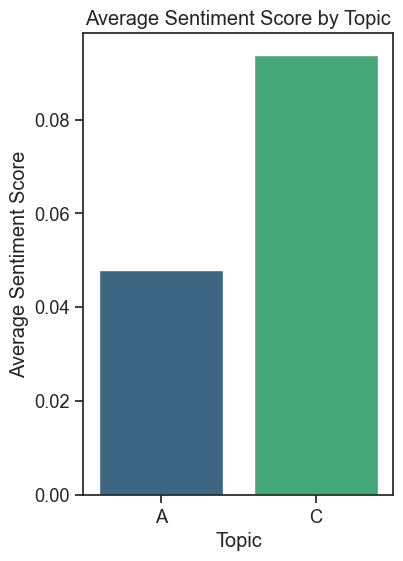

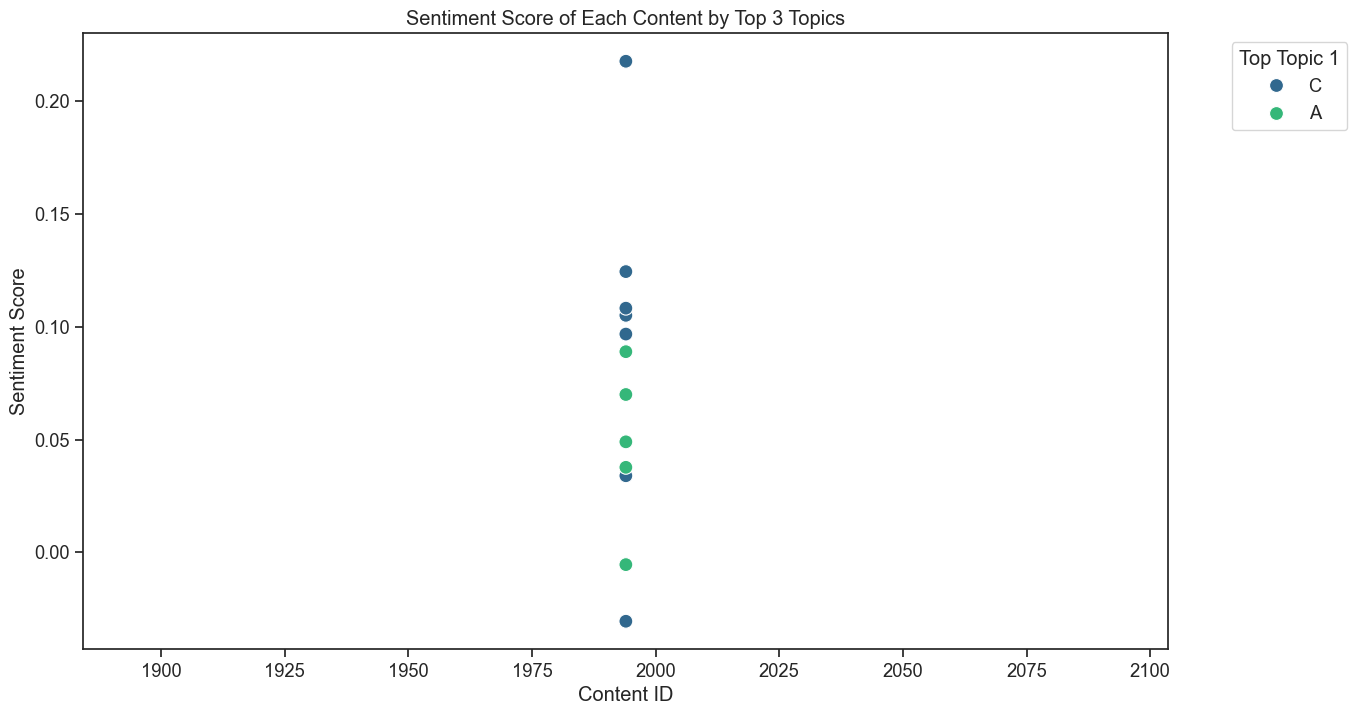

In [ ]:

# Group by top_topic_1 and calculate the mean sentiment score for each topic
average_sentiment = data_cleaned.groupby('top_topic_1')['sentiment_score'].mean().reset_index()

# Rename columns for better readability
average_sentiment.columns = ['Topic', 'Average Sentiment Score']

# Plot the average sentiment score for each topic
plt.figure(figsize=(4, 6))
sns.barplot(x='Topic', y='Average Sentiment Score', data=average_sentiment, palette='viridis')
plt.title('Average Sentiment Score by Topic')
plt.xlabel('Topic')
plt.ylabel('Average Sentiment Score')
plt.show()

# Scatter plot for each content's sentiment score and its top 3 topics
plt.figure(figsize=(14, 8))
sns.scatterplot(x='year', y='sentiment_score', hue='top_topic_1', data=data_cleaned, palette='viridis', legend='full', s=100)
plt.title('Sentiment Score of Each Content by Top 3 Topics')
plt.xlabel('Content ID')
plt.ylabel('Sentiment Score')
plt.legend(title='Top Topic 1', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


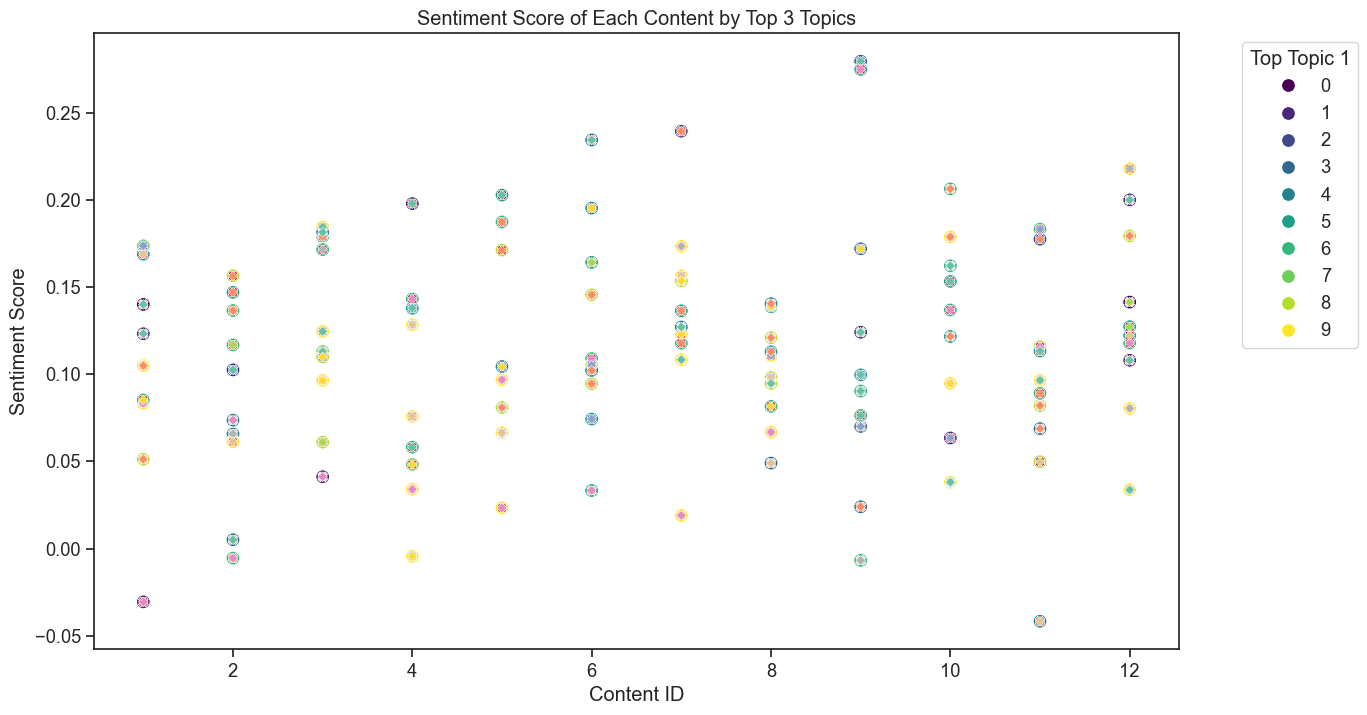

In [95]:

# Scatter plot for each content's sentiment score and its top 3 topics
plt.figure(figsize=(14, 8))
sns.scatterplot(x='month', y='sentiment_score', hue='top_topic_1', data=data_cleaned, palette='viridis', legend='full', s=100)
sns.scatterplot(x='month', y='sentiment_score', hue='top_topic_2', data=data_cleaned, palette='coolwarm', legend=False, s=50, marker='X')
sns.scatterplot(x='month', y='sentiment_score', hue='top_topic_3', data=data_cleaned, palette='Set2', legend=False, s=25, marker='D')
plt.title('Sentiment Score of Each Content by Top 3 Topics')
plt.xlabel('Content ID')
plt.ylabel('Sentiment Score')
plt.legend(title='Top Topic 1', bbox_to_anchor=(1.05, 1), loc='upper left')
plt.show()


In [114]:
!pip install wordcloud

  Obtaining dependency information for wordcloud from https://files.pythonhosted.org/packages/f5/b0/247159f61c5d5d6647171bef84430b7efad4db504f0229674024f3a4f7f2/wordcloud-1.9.3-cp311-cp311-win_amd64.whl.metadata
   ---------------------------------------- 0.0/300.2 kB ? eta -:--:--
   ---------- ----------------------------- 81.9/300.2 kB 2.2 MB/s eta 0:00:01
   ---------------------------------------- 300.2/300.2 kB 4.6 MB/s eta 0:00:00


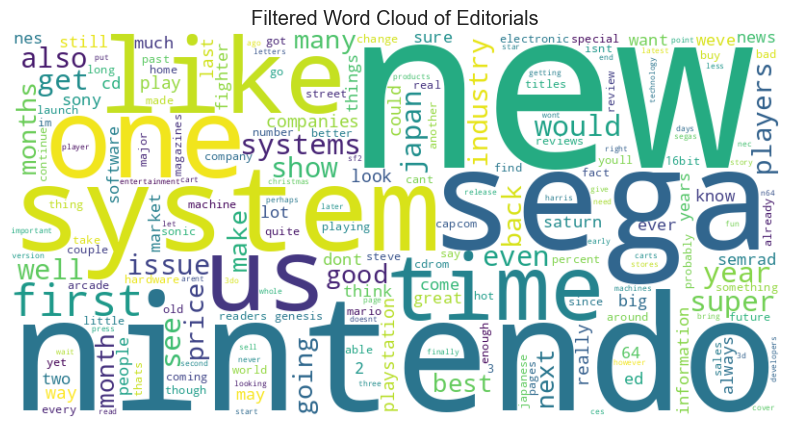

In [ ]:
# Load the dataset
editor_data = pd.read_csv(file_path)

# Combine all tokens into a single list
all_tokens = []
for tokens in editor_data['tokens']:
    tokens_list = eval(tokens)  # Convert string representation of list back to a list
    all_tokens.extend(tokens_list)

# Calculate word frequencies
word_freq = Counter(all_tokens)

# Create a DataFrame for better display
word_freq_df = pd.DataFrame(word_freq.items(), columns=['Word', 'Frequency']).sort_values(by='Frequency', ascending=False)

# Remove specified high-frequency stopwords
stopwords = {'game', 'games', 'gaming', 'video', 'egm', 'magazine'}
filtered_tokens = [word for word in all_tokens if word not in stopwords]

# Recalculate word frequencies after removing stopwords
filtered_word_freq = Counter(filtered_tokens)

# Create a DataFrame for the filtered word frequencies
filtered_word_freq_df = pd.DataFrame(filtered_word_freq.items(), columns=['Word', 'Frequency']).sort_values(by='Frequency', ascending=False)

# Generate the word cloud
filtered_wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(filtered_word_freq)

# Display the word cloud
plt.figure(figsize=(10, 5))
plt.imshow(filtered_wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('Filtered Word Cloud of Editorials')
plt.show()

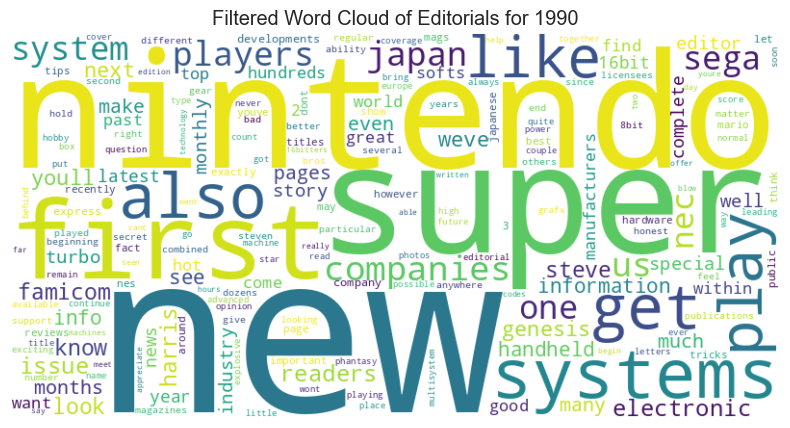

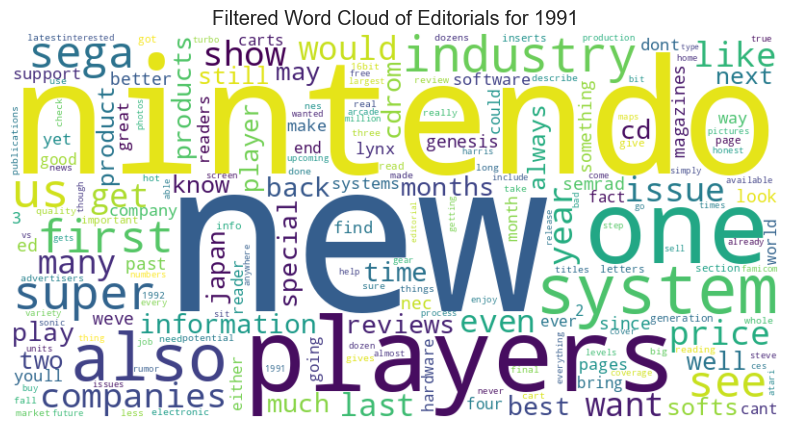

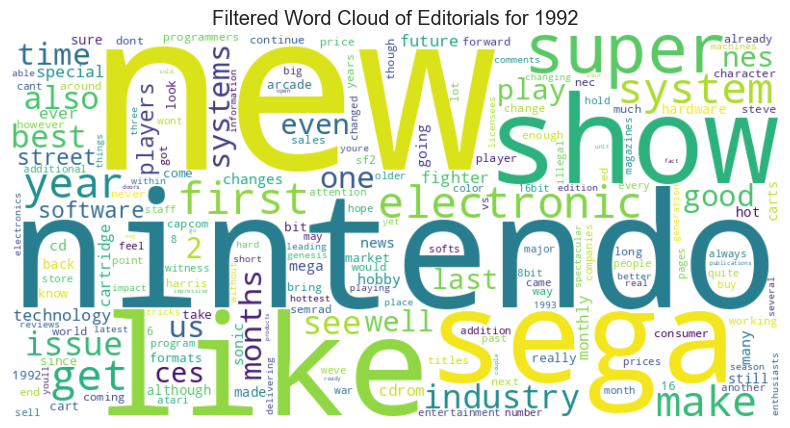

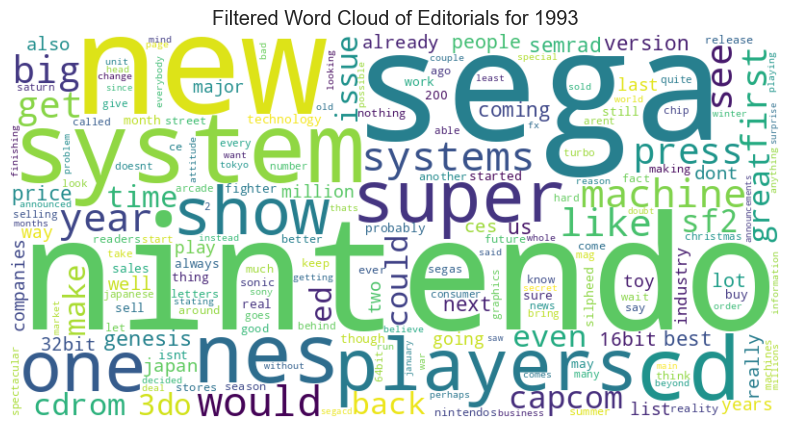

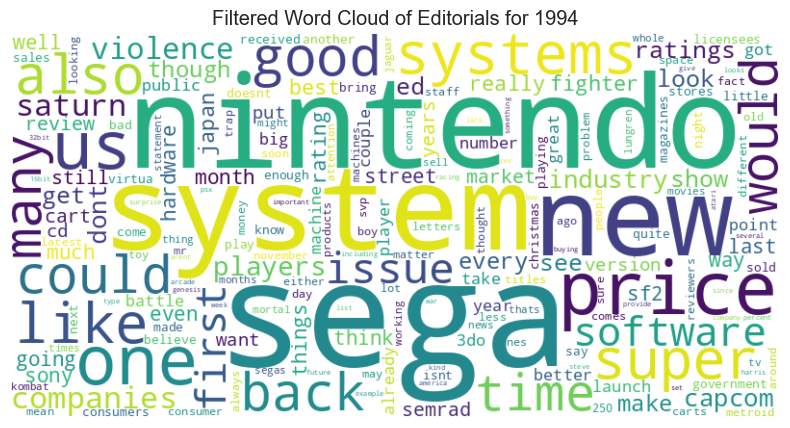

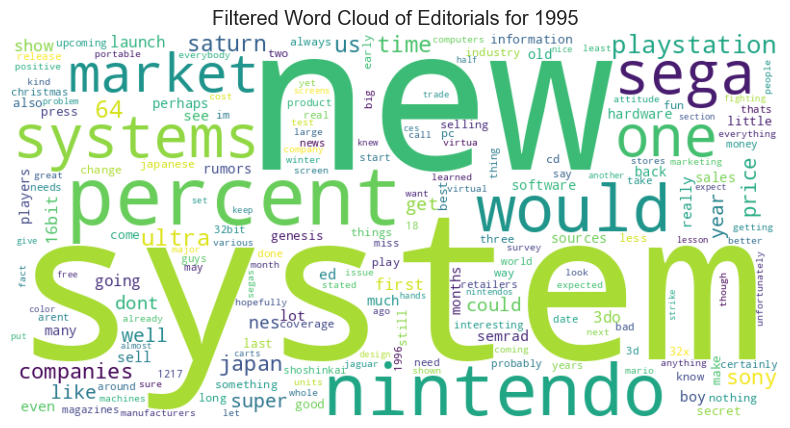

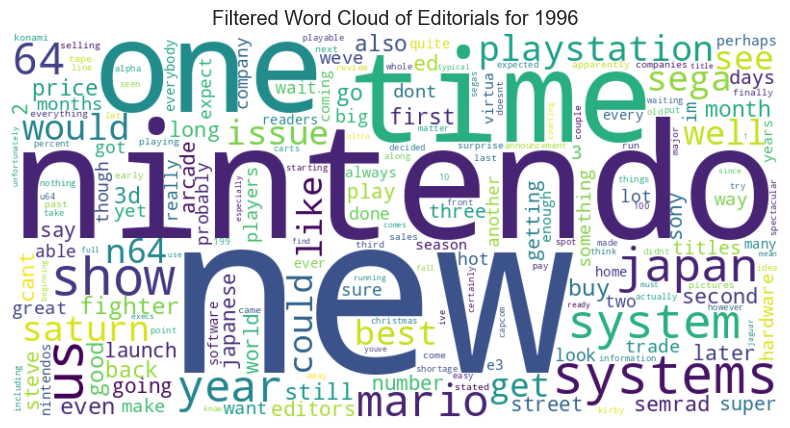

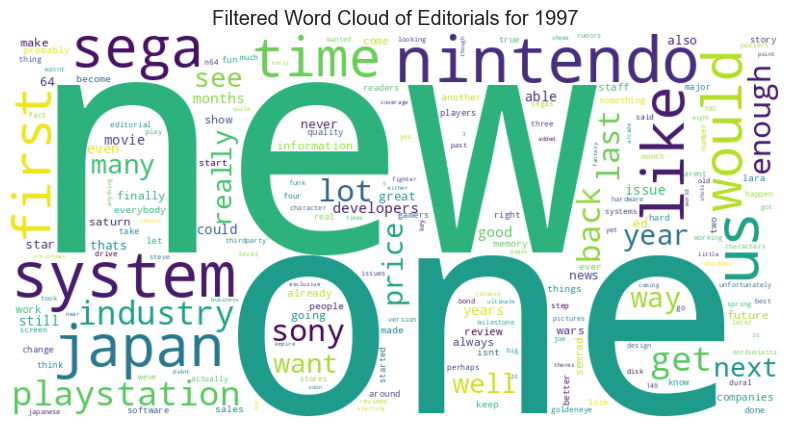

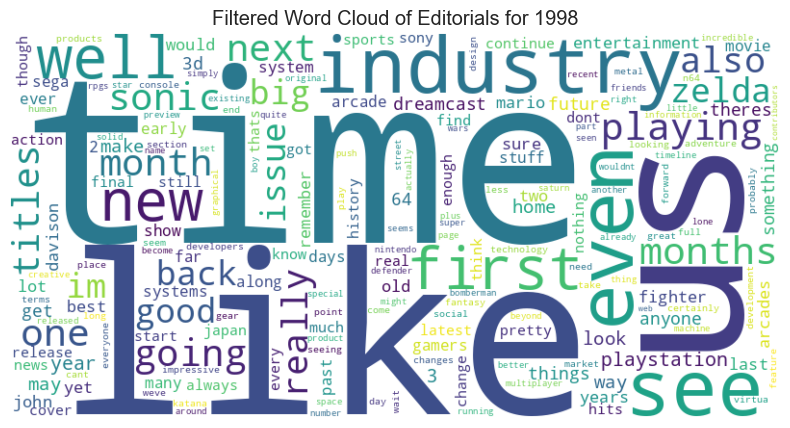

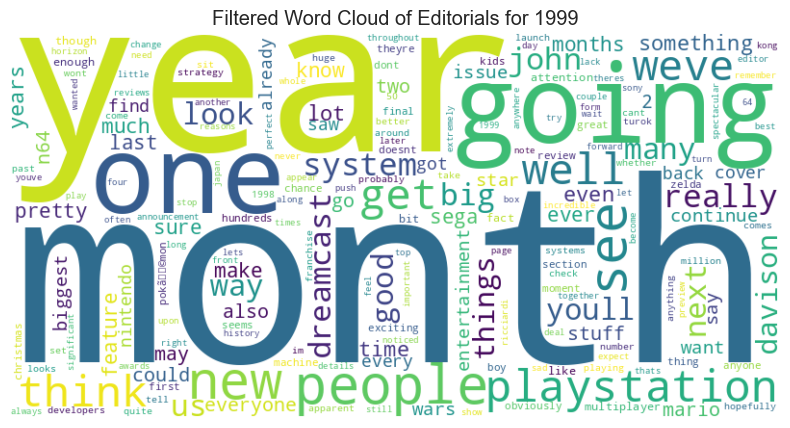

In [ ]:
grouped_by_year = editor_data.groupby('year')

for year, group in grouped_by_year:
    # Combine all tokens for the current year into a single list
    year_tokens = []
    for tokens in group['tokens']:
        tokens_list = eval(tokens)  # Convert string representation of list back to a list
        year_tokens.extend(tokens_list)

    # Calculate word frequencies
    year_word_freq = Counter(year_tokens)

    # Filter out specified high-frequency stopwords
    year_filtered_tokens = [word for word in year_tokens if word not in stopwords]
    year_filtered_word_freq = Counter(year_filtered_tokens)

    # Generate word cloud for the current year
    year_filtered_wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(year_filtered_word_freq)

    # Display the word cloud
    plt.figure(figsize=(10, 5))
    plt.imshow(year_filtered_wordcloud, interpolation='bilinear')
    plt.axis('off')
    plt.title(f'Filtered Word Cloud of Editorials for {year}')
    plt.show()

Overall Type-Token Ratio (TTR): 0.2066
year_month
1990_1     0.829596
1990_10    0.778169
1990_11    0.751748
1990_12    0.862222
1990_2     0.772277
             ...   
1999_5     0.817490
1999_6     0.867220
1999_7     0.848315
1999_8     0.826816
1999_9     0.817647
Name: tokens, Length: 120, dtype: float64


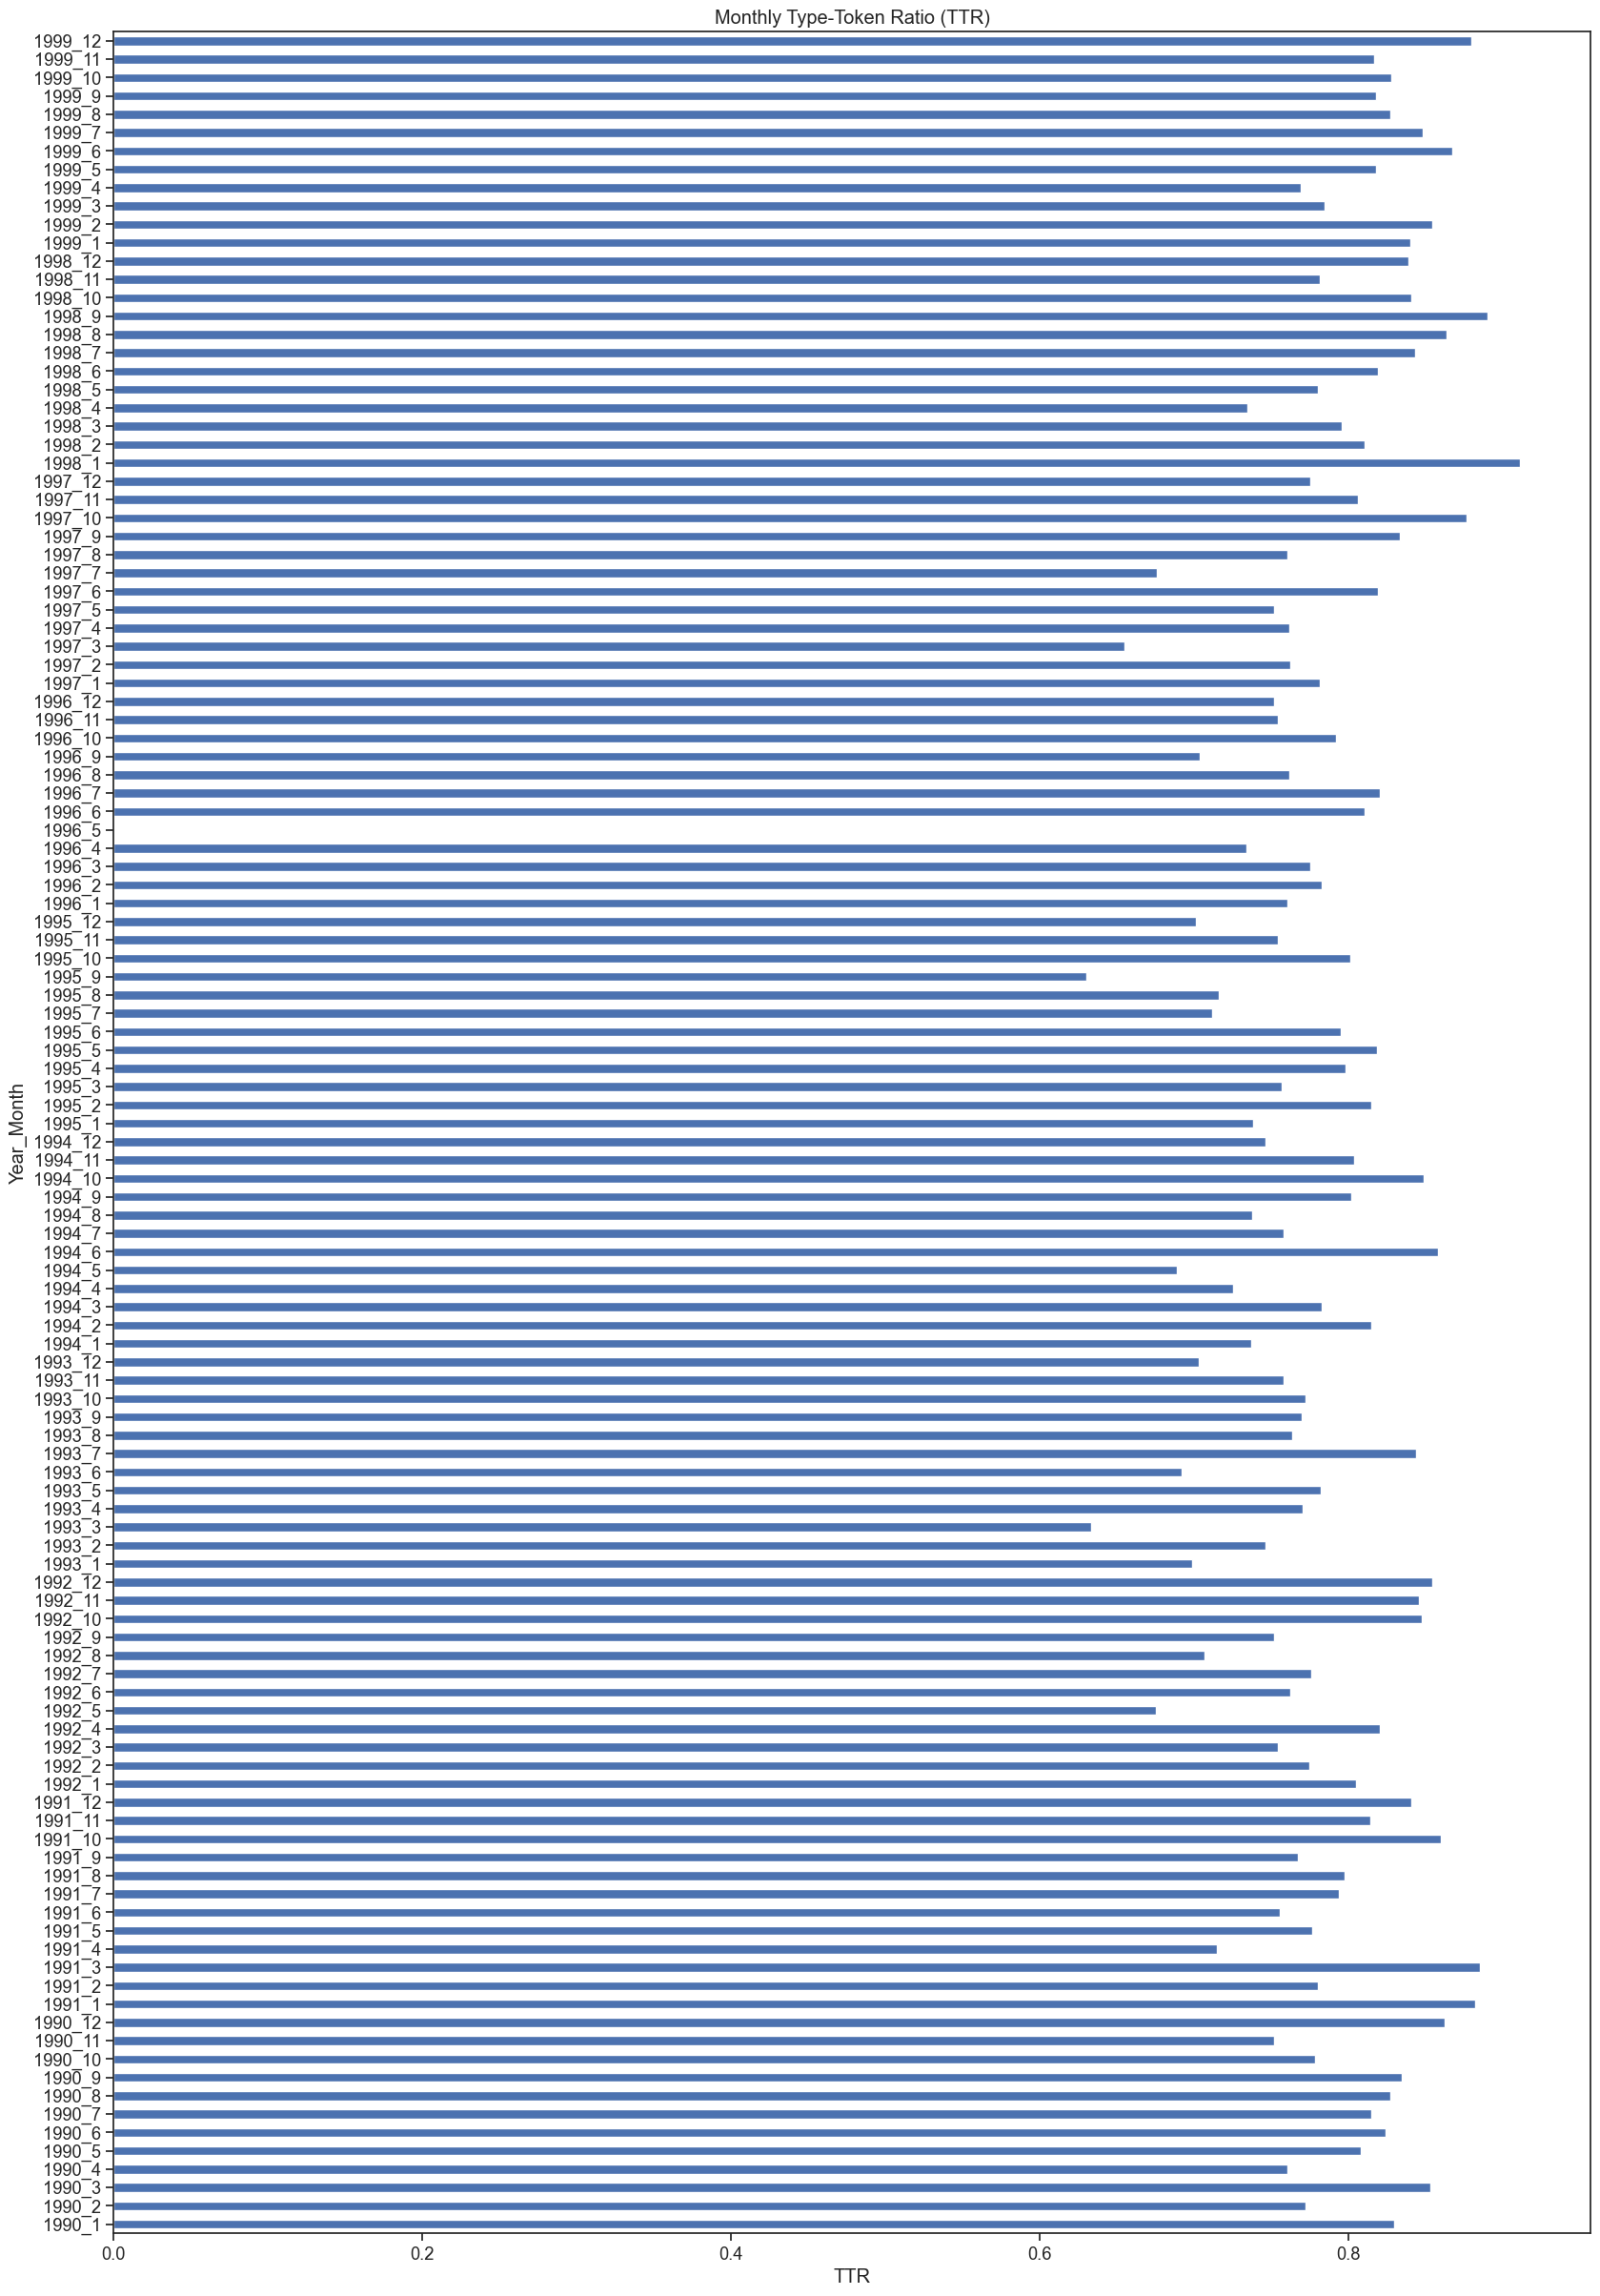

In [ ]:

# Load the uploaded CSV file
editor_data = pd.read_csv(file_path)

# List of high-frequency words to exclude
stopwords = {'game', 'games', 'gaming', 'video', 'egm', 'magazine'}

# Function to calculate Type-Token Ratio (TTR)
def calculate_ttr(tokens):
    filtered_tokens = [word for word in tokens if word not in stopwords]
    unique_words = set(filtered_tokens)
    total_words = len(filtered_tokens)
    return len(unique_words) / total_words if total_words > 0 else 0

# Combine all tokens into one list
all_tokens = []
for tokens in editor_data['tokens']:
    tokens_list = eval(tokens)  # Convert the string representation of the list back to a list
    all_tokens.extend(tokens_list)

# Calculate overall TTR
overall_ttr = calculate_ttr(all_tokens)
print(f"Overall Type-Token Ratio (TTR): {overall_ttr:.4f}")

# Sort editor_data by 'id' column
editor_data.sort_values(by='id', inplace=True)

# Calculate monthly TTR and group by year_month
editor_data['year_month'] = editor_data['year'].astype(str) + '_' + editor_data['month'].astype(str)
ttr_by_month = editor_data.groupby('year_month')['tokens'].apply(lambda x: calculate_ttr(sum([eval(tokens) for tokens in x], [])))

# Display monthly TTR
print(ttr_by_month)

# Visualize TTR with horizontal bar plot (TTR on the x-axis and year_month on the y-axis)
plt.figure(figsize=(20, 30))
# Use sorted index based on 'id' to maintain dataset order
sorted_index = editor_data.sort_values(by='id')['year_month']
ttr_by_month.reindex(sorted_index).plot(kind='barh', title='Monthly Type-Token Ratio (TTR)')
plt.xlabel('TTR')
plt.ylabel('Year_Month')
plt.show()


Year: 1990, Type-Token Ratio (TTR): 0.4668
Year: 1991, Type-Token Ratio (TTR): 0.4680
Year: 1992, Type-Token Ratio (TTR): 0.4372
Year: 1993, Type-Token Ratio (TTR): 0.4369
Year: 1994, Type-Token Ratio (TTR): 0.4653
Year: 1995, Type-Token Ratio (TTR): 0.4554
Year: 1996, Type-Token Ratio (TTR): 0.4519
Year: 1997, Type-Token Ratio (TTR): 0.4797
Year: 1998, Type-Token Ratio (TTR): 0.5183
Year: 1999, Type-Token Ratio (TTR): 0.5134


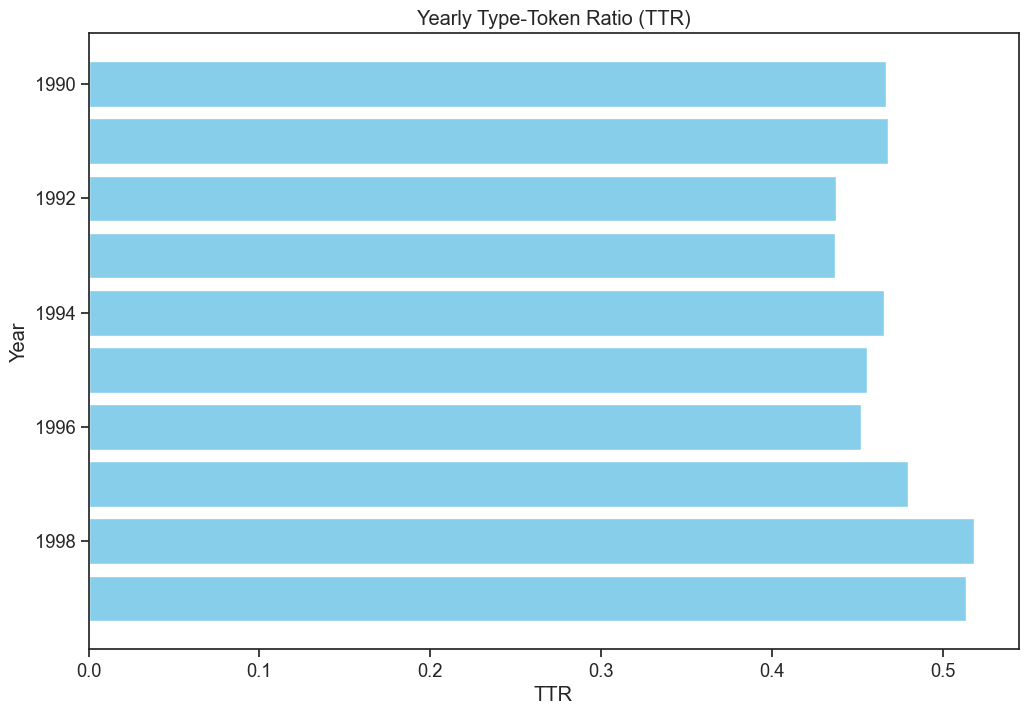

In [ ]:

# Load the uploaded CSV file
editor_data = pd.read_csv(file_path)

# List of high-frequency words to exclude
stopwords = {'game', 'games', 'gaming', 'video', 'egm', 'magazine'}

# Function to calculate Type-Token Ratio (TTR) for a list of tokens
def calculate_ttr(tokens):
    filtered_tokens = [word for word in tokens if word not in stopwords]
    unique_words = set(filtered_tokens)
    total_words = len(filtered_tokens)
    return len(unique_words) / total_words if total_words > 0 else 0

# Combine all tokens into one list per year
tokens_by_year = {}
for idx, row in editor_data.iterrows():
    year = row['year']
    tokens = eval(row['tokens'])
    if year not in tokens_by_year:
        tokens_by_year[year] = []
    tokens_by_year[year].extend(tokens)

# Calculate TTR for each year
ttr_by_year = {}
for year, tokens in tokens_by_year.items():
    ttr_by_year[year] = calculate_ttr(tokens)

# Display yearly TTR
for year, ttr in ttr_by_year.items():
    print(f"Year: {year}, Type-Token Ratio (TTR): {ttr:.4f}")

# Visualize TTR with horizontal bar plot (TTR on the x-axis and year on the y-axis)
plt.figure(figsize=(12, 8))
years = sorted(ttr_by_year.keys())  # Sort years
ttrs = [ttr_by_year[year] for year in years]
plt.barh(years, ttrs, color='skyblue')
plt.title('Yearly Type-Token Ratio (TTR)')
plt.xlabel('TTR')
plt.ylabel('Year')
plt.gca().invert_yaxis()  # Invert y-axis to have the earliest year at the top
plt.show()


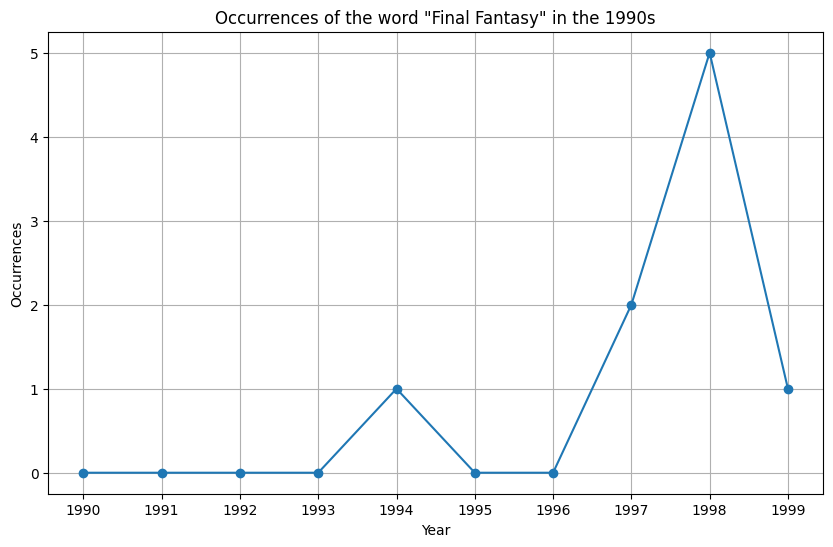

In [ ]:
data = df
# Filter the dataframe to only include rows from the 1990s
data_90s = data[(data['year'] >= 1990) & (data['year'] < 2000)]

# Count the occurrences of the word 'Mario' in each year
data_90s['mario_count'] = data_90s['content'].str.lower().str.count('final fantasy')
mario_counts = data_90s.groupby('year')['mario_count'].sum().reset_index()

# Plot the data
plt.figure(figsize=(10, 6))
plt.plot(mario_counts['year'], mario_counts['mario_count'], marker='o', linestyle='-')
plt.title('Occurrences of the word "Final Fantasy" in the 1990s')
plt.xlabel('Year')
plt.ylabel('Occurrences')
plt.grid(True)
plt.xticks(range(1990, 2000))
plt.show()
